# M12a · Espaces vectoriels et applications linéaires — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m12a_espaces_vectoriels/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M12a.1 à M12a.13, M12a.20, M12a.21 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M12a.26 | Tester l'indépendance et extraire une base de l'espace des colonnes · `is_independent, column_space_basis` | 🔨 | ★★ | 20 |
|  | M12a.27 | Une base du noyau, colonne libre par colonne libre · `null_space_basis` | 🔨 | ★★ | 25 |
|  | M12a.28 | Coordonnées dans une base et changement de base · `coordinates, change_of_basis` | 🔨 | ★ | 20 |
|  | M12a.29 | `sympy.Matrix.nullspace`, `columnspace` et `rank` contre tes fonctions | 📦 | ★ | 15 |
| B | M12a.30 | Prédire le rang : matrices aléatoires, produits, colonnes répétées | 🔮 | ★ | 10 |
|  | M12a.31 | Le rang numérique : une colonne presque redondante et le choix de la tolérance | 🔬 | ★★ | 20 |
|  | M12a.32 | Une application linéaire du plan : l'image du carré unité, et ce qu'elle écrase quand son noyau n'est pas nul | 🎨 | ★ | 20 |
| C | M12a.33 | Chasse à l'erreur : une « base » liée, un noyau faux, S⁻¹AS écrit à l'envers | 🐛 | ★ | 15 |
|  | M12a.34 | Un test de propriété : A fois une base du noyau donne 0, et le théorème du rang sur des matrices aléatoires | 🛠️ | ★ | 15 |
|  | M12a.35 | Défi : retrouver les relations linéaires exactes cachées entre les colonnes d'un tableau, sans en inventer | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : sous-espaces, combinaisons et indépendance, bases et coordonnées, rangs, matrices d'applications et composées, noyaux, images et solutions d'un système, changement de base, application affine et sa réciproque, dérivation des polynômes, une feature redondante, un encodeur qui écrase une direction.
- Écrire les cinq fonctions de `mymath/linmaps.py` et les tester, puis comparer avec SymPy et NumPy.
- Prédire des rangs, mesurer le rang numérique, dessiner ce qu'écrase une application, chasser des erreurs, tester des propriétés, retrouver des relations cachées.

**Rappel express.** Sous-espace : $\mathbf{0}$ dedans, stable par $\lambda\mathbf{x} + \mu\mathbf{y}$ ; libre : chaque colonne de $[\mathbf{v}_1 \cdots \mathbf{v}_k]$ porte un pivot ; coordonnées : $\mathbf{B}\mathbf{c} = \mathbf{v}$ ; $\operatorname{rg}\mathbf{A} = \operatorname{rg}\mathbf{A}^\top$, $\operatorname{rg}(\mathbf{A}\mathbf{B}) \le \min(\operatorname{rg}\mathbf{A}, \operatorname{rg}\mathbf{B})$ ; colonne $j$ de la matrice de $f$ = $f(\mathbf{e}_j)$ ; « $f$ puis $g$ » = $\mathbf{B}\mathbf{A}$ ; $\dim\ker\mathbf{A} + \operatorname{rg}\mathbf{A} = n$ ; solutions de $\mathbf{A}\mathbf{x} = \mathbf{b}$ = $\mathbf{x}_p + \ker\mathbf{A}$ ; nouvelle base : $\mathbf{S}^{-1}\mathbf{A}\mathbf{S}$ ; $\varphi^{-1}(\mathbf{y}) = \mathbf{A}^{-1}(\mathbf{y} - \mathbf{b})$.

## Partie 0 · Vérifier tes exercices papier (✏️ M12a.1 à M12a.13, 🔗 M12a.20 et M12a.21)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une liste `[0, -2, 5]` pour un vecteur, des numéros de colonnes ou une forme, une liste de lignes `[[1, 0], [-2, 3]]` pour une matrice, ou `True` / `False`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly (SymPy) from the statements
import numpy as np
import sympy


def exact(values):
    """SymPy or NumPy numbers as Python ints when whole, else floats."""
    return [int(v) if v == int(v) else float(v) for v in values]


def matrix(M):
    """A matrix as a list of rows of exact numbers."""
    return [exact(row) for row in sympy.Matrix(M).tolist()]


def rank(M):
    return int(sympy.Matrix(np.asarray(M).tolist()).rank())


def kernel(M):
    """The basis of the kernel given by the reduced form (one vector per free column), as lists."""
    return [exact(v) for v in sympy.Matrix(np.asarray(M).tolist()).nullspace()]


def coords(columns, v):
    """The exact coordinates c with [columns] c = v (independent columns, v in their span)."""
    B = sympy.Matrix(np.column_stack(columns).tolist())
    c = (B.T * B).solve(B.T * sympy.Matrix(list(v)))
    assert B * c == sympy.Matrix(list(v)), "v is not in the span"
    return exact(c)


U1_2, U2_2, B_2 = np.array([1, -1, 2]), np.array([3, 0, 1]), np.array([-1, -2, 3])                    # M12a.2
V1_3, V2_3, V3_3 = np.array([1, 2, -1]), np.array([0, 1, 3]), np.array([2, 3, -5])                    # M12a.3
A_4 = np.column_stack([[1, 0, 2], [2, 0, 4], [0, 1, 1], [1, 1, 3], [1, -1, 0]])                       # M12a.4
U_4, V_4 = np.array([1, 2, -2]), np.array([0, 1, -1])
B_5 = np.column_stack([[1, 0, 1], [1, 1, 0], [0, 1, 1]])                                              # M12a.5
P1_5, P2_5 = np.array([1, 2, 0]), np.array([0, 1, -1])
A_6 = np.array([[1, 2, 0, -1], [2, 4, 1, 1], [3, 6, 1, 0]])                                          # M12a.6
C_6 = np.array([[-2, 1, 1], [1, 0, 0], [0, -3, 0], [0, 1, 0]])
X_6 = np.array([[2, 1, 5], [4, 0, 3], [3, 2, 1]])
F_7 = np.array([[1, -2, 1], [3, 0, 1]])                                                             # M12a.7
G_7 = np.column_stack([(np.array([3, 1]) + np.array([1, -3])) // 2, (np.array([3, 1]) - np.array([1, -3])) // 2])
A_8, B_8 = np.array([[3, 0], [0, 1]]), np.array([[1, 2], [0, 1]])                                    # M12a.8
A_9 = np.array([[1, 1, 1, 3], [2, 1, 0, 5], [1, -1, -3, 1]])                                        # M12a.9
A_10 = np.array([[1, 0, 2, -1], [0, 1, -1, 3], [1, 1, 1, 2]])                                       # M12a.10
B_10 = np.array([4, -1, 3])
XP_10 = np.array([4, -1, 0, 0])
assert np.array_equal(A_10 @ XP_10, B_10)
K1_10, K2_10 = (np.array(k) for k in kernel(A_10))
A_11, S_11 = np.array([[4, -2], [1, 1]]), np.column_stack([[1, 1], [2, 1]])                          # M12a.11
A_12, B_12 = np.array([[2, 3], [1, 2]]), np.array([-1, 4])                                           # M12a.12


def phi_12(x):
    return (A_12 @ np.array(x) + B_12).tolist()


D_13 = np.array([[0, 1, 0, 0], [0, 0, 2, 0], [0, 0, 0, 3], [0, 0, 0, 0]])                          # M12a.13
X_20 = np.array([[12, 30, 42], [25, 15, 40], [8, 50, 58], [20, 20, 40]])                            # M12a.20
W_20 = np.array([0.5, 1, 0])
E_21, D_21 = np.array([[1, 1, 0], [0, 1, -1]]), np.array([[1, -1], [0, 1], [0, 0]])                  # M12a.21

**Ex M12a.1 — Reconnaître des sous-espaces de ℝ³ et de l'espace des polynômes**

In [3]:
wbm.record("M12a.1a", True, mistakes={"teste les trois conditions : (0, 0, 0) vérifie-t-il l'équation ? et la somme de deux solutions ?": False})
wbm.record("M12a.1b", False, mistakes={"teste d'abord le vecteur nul": True})
wbm.record("M12a.1c", True, mistakes={"U₃ est formé des multiples d'un même vecteur : vérifie les trois conditions sur cette écriture": False})
wbm.record("M12a.1d", False, mistakes={"cherche deux vecteurs de U₄ dont la somme n'y est pas (essaie des vecteurs faits de 0 et de 1)": True})
wbm.record("M12a.1e", False, mistakes={"multiplie un vecteur de U₅ par −1": True})
wbm.record("M12a.1f", True, mistakes={"si P(1) = 0 et Q(1) = 0, que vaut (λP + μQ)(1) ?": False})
wbm.record("M12a.1g", False, mistakes={"le polynôme nul vérifie-t-il la condition ?": True})
wbm.record("M12a.1h", [4, -2, 6], mistakes={"la première coordonnée est 2t, pas t : trouve d'abord t": [8, -4, 12]})

WBM_ANSWER {"hash": "df224cdf16b20a84925f6978e8ffed80d8071159b0a96e92b080b13dd1d1363f", "id": "M12a.1a", "kind": "bool", "mistakes": {"af7718dc73d287c21a3d84c291fc4bf221a7d2f2309fc544e256d82bfc359818": "teste les trois conditions : (0, 0, 0) vérifie-t-il l'équation ? et la somme de deux solutions ?"}}
📝 Ex M12a.1a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "c39ae1d6c73edd12e3721157e88118f484248343454675e622ac8b1b9d54c520", "id": "M12a.1b", "kind": "bool", "mistakes": {"5877aa92a812c24e3a6c9871e399551423bc766ea0e14c04f61228e37025c4cd": "teste d'abord le vecteur nul"}}
📝 Ex M12a.1b : réponse enregistrée (bool).
WBM_ANSWER {"hash": "f5e6ce9c41d84f213fad3922e9835b39ff6630e101a2aa555d0e0c343129a5f1", "id": "M12a.1c", "kind": "bool", "mistakes": {"6c71bb04c593949a4624ec5f6fcf55dc445572e71ef971a47e0b18ca855867db": "U₃ est formé des multiples d'un même vecteur : vérifie les trois conditions sur cette écriture"}}
📝 Ex M12a.1c : réponse enregistrée (bool).
WBM_ANSWER {"hash": "1247611f424

**Ex M12a.2 — Écrire un vecteur comme combinaison linéaire : un système à résoudre**

In [4]:
wbm.record("M12a.2a", coords([U1_2, U2_2], B_2), mistakes={"garde l'ordre de l'énoncé : le premier nombre multiplie le premier vecteur": [-1, 2]})
wbm.record("M12a.2b", False, mistakes={"résous avec deux équations, puis vérifie la troisième avec les nombres trouvés": True})
wbm.record("M12a.2c", 1, mistakes={"la deuxième coordonnée de λ₁u₁ + λ₂u₂ est −λ₁ : attention au signe": -1})
wbm.record("M12a.2d", [3 * x for x in kernel([U1_2, U2_2])[0]], mistakes={"n doit vérifier n · u₁ = 0 et n · u₂ = 0 : vérifie les deux produits scalaires": [1, -5, 3]})
wbm.record("M12a.2e", True, mistakes={"b combine u₁ et u₂ (question a) : u₂ combine-t-il u₁ et b ?": False})
wbm.record("M12a.2f", 1, mistakes={"on demande le nombre de vecteurs à ajouter, pas le total": 3})

WBM_ANSWER {"decimals": 0, "element_hashes": ["c79275c461c33f811fad2bf0ff31485b7a91ca57772378b1589de5eb856deac0", "b8af71b249575360f1b7ad62f4ca6bb22b2a9f7131548db60a3f89d268679ee6"], "hash": "b5df1b2e35eaf9b1277366dde31aae0da3d516dfa231fbb2e111373eed74f0c6", "id": "M12a.2a", "integer": true, "kind": "array", "mistakes": {"7b3a077f7371bf9d3becb7c0d7ec56183900e39659f6dd1129361b39c531a809": "garde l'ordre de l'énoncé : le premier nombre multiplie le premier vecteur"}, "shape": [2]}
📝 Ex M12a.2a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "c31f3e19fa14604018a434ad5c45de274ce16fce148426c7f0b1df01766e1796", "id": "M12a.2b", "kind": "bool", "mistakes": {"c659d5e20b866904e0db62c8a42e59b1b71f189b1ae5c285bea000a2924e19da": "résous avec deux équations, puis vérifie la troisième avec les nombres trouvés"}}
📝 Ex M12a.2b : réponse enregistrée (bool).
WBM_ANSWER {"hash": "859d8344bb4246fc7b3beb4ca61111f5ccdb7ee18b5c0c85b3bb2bca5bb9cf56", "id": "M12a.2c", "kind": "int", "magnitude":

**Ex M12a.3 — L'indépendance de trois vecteurs de ℝ³ par le pivot de Gauss**

In [5]:
wbm.record("M12a.3a", rank(np.column_stack([V1_3, V2_3, V3_3])), mistakes={"fais le pivot de Gauss jusqu'au bout : une ligne peut s'annuler": 3})
wbm.record("M12a.3b", False, mistakes={"compare le rang au nombre de vecteurs": True})
wbm.record("M12a.3c", coords([V1_3, V2_3], V3_3), mistakes={"garde l'ordre de l'énoncé : le premier nombre multiplie le premier vecteur": [-1, 2]})
wbm.record("M12a.3d", kernel(np.column_stack([V1_3, V2_3, V3_3]))[0], mistakes={"x₁v₁ + x₂v₂ + v₃ = 0 : les coefficients de v₁ et v₂ sont les opposés de ceux de c)": [2, -1, 1]})
wbm.record("M12a.3e", -7, mistakes={"(1, 0, k) doit combiner v₁ et v₂ : trouve les coefficients avec les deux premières coordonnées, puis calcule la troisième": 7})
wbm.record("M12a.3f", rank(np.column_stack([V1_3, V2_3, [2, 3, -4]])) == 3, mistakes={"calcule le rang de la nouvelle famille : le troisième vecteur a changé": False})

WBM_ANSWER {"hash": "c5f242cbff622f5fd6e11fa75a6fcb2880cbf67130192b1fdce8ca07d83f224e", "id": "M12a.3a", "kind": "int", "magnitude": 0, "mistakes": {"63f25159fb526d64976707aa2b02b4505df86b91a1ade9da3dd530d91c68b6b8": "fais le pivot de Gauss jusqu'au bout : une ligne peut s'annuler"}, "sign": 1}
📝 Ex M12a.3a : réponse enregistrée (int).
WBM_ANSWER {"hash": "1c56b55ba4264e32ac78aaa3bc3544bb76fa0ed1ef9e21fffefe79ed4710893a", "id": "M12a.3b", "kind": "bool", "mistakes": {"000d3cec2b09268b288c3a0326fde20822f689a049595572b77b83cb4f28bfa3": "compare le rang au nombre de vecteurs"}}
📝 Ex M12a.3b : réponse enregistrée (bool).
WBM_ANSWER {"decimals": 0, "element_hashes": ["83e9290f98bd9c8519345857622e5a5727bd61b7cc16eeb35afa499603fe22a3", "514c4c24b46a378febfd7c7a0a83a879faab19f00e2910c4c6a9bbb6ae4a2b25"], "hash": "6aa04c498283cdc8e1f37953e657fca28f14bcc95f765d7529b6625c72290bf7", "id": "M12a.3c", "integer": true, "kind": "array", "mistakes": {"21a0f0408feaccbaa2ab02fdfed92f97cee3393c4e5107113a7

**Ex M12a.4 — Extraire une base d'une famille génératrice, compléter une famille libre**

In [6]:
wbm.record("M12a.4a", rank(A_4), mistakes={"compte les pivots, pas les vecteurs : deux d'entre eux sont redondants": 5})
wbm.record("M12a.4b", [p + 1 for p in sympy.Matrix(A_4).rref()[1]], mistakes={"les colonnes se numérotent à partir de 1": [0, 2, 4], "garde les colonnes qui portent un pivot, pas les premières": [1, 2, 3]})
wbm.record("M12a.4c", coords([A_4[:, 0], A_4[:, 2]], A_4[:, 3]))
wbm.record("M12a.4d", rank(A_4[:, :4]), mistakes={"la dimension compte les vecteurs libres, pas tous les vecteurs": 4})
wbm.record("M12a.4e", next(j + 1 for j in range(3) if rank(np.column_stack([U_4, V_4, np.eye(3, dtype=int)[:, j]])) == 3), mistakes={"vérifie que (u, v, e₁) est libre : calcule son rang": 1})
wbm.record("M12a.4f", coords([U_4, V_4], [1, 0, 0]), mistakes={"garde l'ordre de l'énoncé : le premier nombre multiplie le premier vecteur": [-2, 1]})

WBM_ANSWER {"hash": "c04cd71e79405053c5a3781cc8084eb8d4c9725772e75164f3af3235ba6a5a39", "id": "M12a.4a", "kind": "int", "magnitude": 0, "mistakes": {"c942d1d8e6930b84003f3344174f73b9caee5780aa07598dba81a5bce71f515d": "compte les pivots, pas les vecteurs : deux d'entre eux sont redondants"}, "sign": 1}
📝 Ex M12a.4a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["5992270884cd49a07abd92747c3643893c5a5fed1e5a2c2399139fe1c09a7f4d", "219a7ef5c549b332591b4bb5b1426c339892fdffde29b700eea001a62a8e6795", "b8d3452733117781ad0cc2a9eda01b983befbdf20984ecc5738186b5d61f24ca"], "hash": "109c4f04a29e97fc861c7659fc678ff396191651fdca4be07fc188eede52a42d", "id": "M12a.4b", "integer": true, "kind": "array", "mistakes": {"3f8c05a6b551db3022b932c8382f8f12febcd2383b1e47c476b32dcaf3032a7b": "garde les colonnes qui portent un pivot, pas les premières", "eaaf81f90fd53f7d8bea07d2c672929cc2efaf6683705a7d8373334d3b7c8a78": "les colonnes se numérotent à partir de 1"}, "shape": [3]}
📝 Ex M1

**Ex M12a.5 — Les coordonnées d'un vecteur dans une base qui n'est pas la base canonique**

In [7]:
wbm.record("M12a.5a", coords(list(B_5.T), [1, 4, -1]), mistakes={"les vecteurs de base sont les colonnes de B : résous B c = v, pas Bᵀ c = v": exact(sympy.Matrix(B_5.T.tolist()).solve(sympy.Matrix([1, 4, -1])))})
wbm.record("M12a.5b", (B_5 @ np.array([2, -1, 1])).tolist(), mistakes={"le vecteur est 2b₁ − b₂ + b₃ : B fois les coordonnées": exact(sympy.Matrix(B_5.tolist()).solve(sympy.Matrix([2, -1, 1])))})
wbm.record("M12a.5c", [float(x) for x in coords(list(B_5.T), [1, 0, 0])], decimals=1)
wbm.record("M12a.5d", coords([P1_5, P2_5], [2, 7, -3]), mistakes={"l'ordre de la base : p₁, puis p₂": [3, 2]})
wbm.record("M12a.5e", False, mistakes={"trouve les coefficients avec deux coordonnées, puis vérifie la troisième": True})
wbm.record("M12a.5f", coords([B_5[:, 2], B_5[:, 0], B_5[:, 1]], [1, 4, -1]), mistakes={"dans la base (b₃, b₁, b₂), la première coordonnée est celle de b₃": coords(list(B_5.T), [1, 4, -1])})

WBM_ANSWER {"decimals": 0, "element_hashes": ["e3398b76ec5a07d9b04f80b97ffd036fd9a3c265f44a15f7e25e774101bfcbe7", "71a10e1059e08fa0e5e8f1af0893ae508af3103a21e903fd2c438263d6d3b99f", "ab364e21f7dbb5d8cacbe2b41f43c28eeaf5003125b8d5cd125bf995a0c6e004"], "hash": "e2bddd9787c9306b0dd19e575bb38447bc218990026ab97e5c867eb9e7f801b4", "id": "M12a.5a", "integer": true, "kind": "array", "mistakes": {"2ccaa2c7c80bac95a3925d706cc9f2eef61598dc859cee692061123ea9dfb13f": "les vecteurs de base sont les colonnes de B : résous B c = v, pas Bᵀ c = v"}, "shape": [3]}
📝 Ex M12a.5a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["84528e680df5eb68e495627cdc65f17c5befdefc28819cab3ef8848a599a3df4", "49233ff2f516e5537370cc90d17987c35dd41cc69061576795283b8339be8441", "b6f8e2408bb4f629a08228e30f8edfd8e1ff6388dbf72736486038d3b0b6bac7"], "hash": "a0ff21a9c475d238d182c6ae6d0fae871bc8ea3af3b5fe485de3276f9514b2d8", "id": "M12a.5b", "integer": true, "kind": "array", "mistakes": {"

**Ex M12a.6 — Le rang par les colonnes et par les lignes, celui d'un produit, et celui d'un tableau centré**

In [8]:
wbm.record("M12a.6a", rank(A_6), mistakes={"cherche une ligne qui combine les autres": 3})
wbm.record("M12a.6b", rank(A_6.T), mistakes={"le rang de la transposée est celui de la matrice": 3})
wbm.record("M12a.6c", rank(A_6.T @ A_6), mistakes={"rg(AᵀA) = rg(A), même si AᵀA a la forme (4, 4)": 4})
wbm.record("M12a.6d", rank(C_6))
wbm.record("M12a.6e", rank(A_6 @ C_6), mistakes={"min(rg A, rg C) n'est qu'une borne : calcule A fois chaque colonne de C": 2})
wbm.record("M12a.6f", rank(X_6))
wbm.record("M12a.6g", rank(X_6 - X_6.sum(axis=0) // 3), mistakes={"centrer rend les lignes liées : leur somme est nulle": 3})

WBM_ANSWER {"hash": "95cdfe7aa1a43340f2a5f47b64fc29eaffba43c2c3a8da3c1833e2ef43f6b3f5", "id": "M12a.6a", "kind": "int", "magnitude": 0, "mistakes": {"150e9c50c6dab5e4ddb90a1fff4892f8cddf9d8c41ca31798e2b985a175f111d": "cherche une ligne qui combine les autres"}, "sign": 1}
📝 Ex M12a.6a : réponse enregistrée (int).
WBM_ANSWER {"hash": "169aa9992bc3356d9b1a3cc093614e2d2056d4494a8febe69745deee952799d7", "id": "M12a.6b", "kind": "int", "magnitude": 0, "mistakes": {"c3483ab14f5277a847932c22799bb907ea7068c26ac50de10e9fd6abdc8e00e2": "le rang de la transposée est celui de la matrice"}, "sign": 1}
📝 Ex M12a.6b : réponse enregistrée (int).
WBM_ANSWER {"hash": "2a94dce9e2b2b0b778786b29fbc81c903af199f788c20c56f09a184a68b83bb3", "id": "M12a.6c", "kind": "int", "magnitude": 0, "mistakes": {"218066f955a93d577be072e15b7016c2e27416d612bba245ea4c44551ce447f9": "rg(AᵀA) = rg(A), même si AᵀA a la forme (4, 4)"}, "sign": 1}
📝 Ex M12a.6c : réponse enregistrée (int).
WBM_ANSWER {"hash": "3e88f25372d9fc049d69

**Ex M12a.7 — La matrice d'une application linéaire : les images des vecteurs de base**

In [9]:
wbm.record("M12a.7a", F_7.tolist(), mistakes={"la colonne j est f(e_j) : une ligne par coordonnée d'arrivée, une colonne par coordonnée de départ": F_7.T.tolist()})
wbm.record("M12a.7b", F_7[:, 1].tolist())
wbm.record("M12a.7c", (F_7 @ np.array([2, 1, -1])).tolist())
wbm.record("M12a.7d", [2, 5], mistakes={"la forme est (lignes, colonnes) = (arrivée, départ)": [5, 2]})
wbm.record("M12a.7e", G_7.tolist(), mistakes={"les colonnes sont g(e₁) et g(e₂), pas g(1, 1) et g(1, −1)": [[3, 1], [1, -3]], "g(e_j) se range dans la colonne j, pas dans la ligne j": G_7.T.tolist()})
wbm.record("M12a.7f", [[0.5, 0.5], [0.5, 0.5]], decimals=1, mistakes={"projeter e₁ sur la droite dirigée par u = (1, 1) : (e₁ · u / ‖u‖²) u": [[1.0, 1.0], [1.0, 1.0]]})
wbm.record("M12a.7g", False, mistakes={"une application linéaire envoie 0 sur 0": True})

WBM_ANSWER {"decimals": 0, "element_hashes": ["9965b3ad7ed48d98810b81623a9273d70c20f9120bb9266717b2f02ef9db2483", "0807aa164f9ee034c7be3b07516d2c42eb75232130d9daf55c7630e16b89e7e8", "82baa7caa0f810e8bf8f723475a130239dd8dea0ebc8c5338596adfeb9c3cb20", "4760a5546e8817d5b38b4f95c0e0e9d268abed871260fc5e90f422520d91cbd2", "d1a955b285ccfb321d344a13036338e8e3f4a488c20a87a9927b7479a99488e5", "71bb613bddca7c802c8b8021cc41025e887467f03ac57f6557014624a53e48fb"], "hash": "45a3ba209bc21c20257398fb538ef5dbb1e67dd3846c04227a5680c031a20eec", "id": "M12a.7a", "integer": true, "kind": "array", "mistakes": {"5eaf96a24b48f414e1102ca35fea0e20bf7c1aba3ffea91969fa5b02e50b0182": "la colonne j est f(e_j) : une ligne par coordonnée d'arrivée, une colonne par coordonnée de départ"}, "shape": [2, 3]}
📝 Ex M12a.7a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["ce1b7d0d1c1eb5337ac31d44ac32df25ad8ecae9b1ea2446b843847827714347", "da3ca4f5be4175d73f0be2ec34558635e6e141b4378172

**Ex M12a.8 — Composer deux applications du plan, c'est multiplier leurs matrices**

In [10]:
wbm.record("M12a.8a", (B_8 @ A_8).tolist(), mistakes={"« a, puis b » a pour matrice BA : la dernière appliquée à gauche": (A_8 @ B_8).tolist()})
wbm.record("M12a.8b", (A_8 @ B_8).tolist(), mistakes={"« b, puis a » a pour matrice AB : la dernière appliquée à gauche": (B_8 @ A_8).tolist()})
wbm.record("M12a.8c", (B_8 @ A_8 @ np.array([1, 1])).tolist(), mistakes={"applique a d'abord, puis b": (A_8 @ B_8 @ np.array([1, 1])).tolist()})
wbm.record("M12a.8d", False, mistakes={"compare les matrices de a) et de b)": True})
wbm.record("M12a.8e", (B_8 @ B_8).tolist())
wbm.record("M12a.8f", matrix(sympy.Matrix(B_8.tolist()).inv()), mistakes={"l'inverse défait le cisaillement : vérifie que B fois ta matrice donne I": [[1, 2], [0, 1]]})
wbm.record("M12a.8g", matrix(sympy.Matrix((A_8 @ B_8).tolist()).inv()), decimals=4, mistakes={"(AB)⁻¹ = B⁻¹A⁻¹ : l'ordre s'inverse": matrix(sympy.Matrix(A_8.tolist()).inv() * sympy.Matrix(B_8.tolist()).inv())})

WBM_ANSWER {"decimals": 0, "element_hashes": ["8aa80293c1fe2020d5eb107138014a5a2c50fbc05d761fee4fb5167fc1ec2d66", "f92df5183c165203449bba1b29ef7cff08ab0f598ccbb9a0ca0c45367ed5fddf", "82757382229fb60f37280633bf84ae6939bb389aaa2f858ac1ae573f552a828d", "79ddffade29089b2328bf0042e971a0909c7c35fbd15c5786b342735c42cbcbd"], "hash": "e1c9625419852426b9201ecb87f90740123021539c66e4048a762722a4ca0d46", "id": "M12a.8a", "integer": true, "kind": "array", "mistakes": {"27f46097e216519af4d8c5fb352db99c4e0faa1fc470326fb1272dfc3a49c19f": "« a, puis b » a pour matrice BA : la dernière appliquée à gauche"}, "shape": [2, 2]}
📝 Ex M12a.8a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["8fe08d3af7969fe8ebc718c06542d15e7c7b04356869cbf3cdccbadf7380717a", "26fef5538976933f6950ff468baf8f349310e625bb03aca7343acfe9b8e7df5a", "de42efa3af1c885ab283f440f91cb6320c5e10e05142716e9adb1a40d38e6198", "ce654a972bbd36318bf897cf9ffb45298ac1b4e5a854d664175d22e542f5d82a"], "hash": "1d6

**Ex M12a.9 — Noyau et image d'une matrice 3 × 4, et le théorème du rang**

In [11]:
wbm.record("M12a.9a", rank(A_9))
wbm.record("M12a.9b", [p + 1 for p in sympy.Matrix(A_9).rref()[1]], mistakes={"les colonnes se numérotent à partir de 1": [0, 1]})
wbm.record("M12a.9c", A_9.shape[1] - rank(A_9), mistakes={"le théorème du rang : dim ker A = nombre de colonnes − rang": 1})
wbm.record("M12a.9d", kernel(A_9)[0], mistakes={"pour la colonne libre j : x_j = 1, et x_p = −R[i, j] pour le pivot de la ligne i (le signe moins)": [-1, 2, 1, 0]})
wbm.record("M12a.9e", kernel(A_9)[1], mistakes={"pour la colonne libre j : x_j = 1, et x_p = −R[i, j] pour le pivot de la ligne i (le signe moins)": [2, 1, 0, 1]})
wbm.record("M12a.9f", A_9[:, [0, 1]].tolist(), mistakes={"les colonnes de A, pas celles de la forme réduite": [[1, 0], [0, 1], [0, 0]]})
wbm.record("M12a.9g", kernel(A_9[:, [0, 1]].T)[0], mistakes={"n doit être orthogonal aux deux colonnes de f) : vérifie les deux produits scalaires": [-3, 2, 1]})
wbm.record("M12a.9h", True, mistakes={"un vecteur est dans l'image quand son produit scalaire avec n est nul": False})

WBM_ANSWER {"hash": "eb213cae766665eede923910ba632d08e30e25e5691debdb06eab347a289e14c", "id": "M12a.9a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M12a.9a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["21b95383d3848dd3af3b4b98fbc42bd0ea58caf98d777f8d3c9c4e5f4fba8872", "89447b5276698908ff731c4bdf1915a72a549eed36ce0129a1117947695e3086"], "hash": "0dc5b76c4504890c39d354540e0ccdc7e8a6588dd257789794f41967ae226b71", "id": "M12a.9b", "integer": true, "kind": "array", "mistakes": {"c7b0aa9d214fa0c450ff26cd187bb2ef4169114efd14e898e2bbf8b1b3f1193c": "les colonnes se numérotent à partir de 1"}, "shape": [2]}
📝 Ex M12a.9b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "d62221fa26d4f456ab264103653460e0693a34f0b30e93c2f1251354a37733e8", "id": "M12a.9c", "kind": "int", "magnitude": 0, "mistakes": {"08c44e2ba32bd8c266f8ec87fbf2bea65768c78621784b1b7db019a739bc1619": "le théorème du rang : dim ker A = nombre de colonnes − rang"}, "sign": 1}
📝 Ex M12a.9c 

**Ex M12a.10 — Toutes les solutions de A x = b : une solution particulière plus le noyau**

In [12]:
wbm.record("M12a.10a", XP_10.tolist())
wbm.record("M12a.10b", A_10.shape[1] - rank(A_10))
wbm.record("M12a.10c", kernel(A_10)[0], mistakes={"pour la colonne libre j : x_j = 1, et x_p = −R[i, j] pour le pivot de la ligne i (le signe moins)": [2, -1, 1, 0]})
wbm.record("M12a.10d", kernel(A_10)[1], mistakes={"pour la colonne libre j : x_j = 1, et x_p = −R[i, j] pour le pivot de la ligne i (le signe moins)": [-1, 3, 0, 1]})
wbm.record("M12a.10e", (XP_10 + 2 * K1_10 - K2_10).tolist(), mistakes={"une solution est x_p + s k₁ + t k₂ : n'oublie pas la solution particulière": (2 * K1_10 - K2_10).tolist()})
wbm.record("M12a.10f", bool(np.array_equal(A_10 @ np.array([2, 0, 1, 0]), B_10)), mistakes={"calcule A fois ce vecteur et compare à b": False})
wbm.record("M12a.10g", 3, mistakes={"la troisième ligne de A est la somme des deux autres : et pour b ?": -3})
wbm.record("M12a.10h", 0, mistakes={"b doit être dans l'image de A ; sinon, aucune solution": 1})

WBM_ANSWER {"decimals": 0, "element_hashes": ["3661ff7a8f85afa1b9196428466a250e78b6fc98c9d705a56edd2c01b0f83bd9", "f0b19523e1e6242673fceed5fcd388e577352a61e4cf392d42b7bfc5a3243ad2", "27ea245e8bcd681345857bec31f8fb1d388cd98678d9ed50c308c65dbb543291", "9c5358738a0a2679614e20056495031c374c44fdcda1637622e6c379943838e9"], "hash": "dca69f4bdda809839cf466212c8c4362e0e5243351af36d3007e6a9c4653c5c1", "id": "M12a.10a", "integer": true, "kind": "array", "shape": [4]}
📝 Ex M12a.10a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "412c984e891f4a7046f3e72ddbabe83ed7f211aaf860d43d5ccab6b35c5e2ef5", "id": "M12a.10b", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M12a.10b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["f95320686ec4a1e707d0b13f04bbb32438c1671e992aa14dfb7323800845e56c", "fe6f1a2eea38ecef5c9b1d9ee4c6bf7d9df53e02a5e5d59c6358996aa793ac97", "69d2b2b142264991d13ba212129d1667c81594cbb49118b2cfc309df1fb2eb31", "17f735f6b80d0ef2f20778116b30d47fe2b71b2b

**Ex M12a.11 — Une base adaptée qui rend diagonale la matrice d'une application : S⁻¹AS**

In [13]:
wbm.record("M12a.11a", (A_11 @ S_11[:, 0]).tolist())
wbm.record("M12a.11b", (A_11 @ S_11[:, 1]).tolist())
wbm.record("M12a.11c", matrix(sympy.Matrix(S_11.tolist()).inv()), mistakes={"l'inverse 2 × 2 : échange a et d, change le signe de b et de c, divise par ad − bc (ici négatif)": (-np.array(matrix(sympy.Matrix(S_11.tolist()).inv()))).tolist()})
wbm.record("M12a.11d", matrix(sympy.Matrix(S_11.tolist()).inv() * sympy.Matrix(A_11.tolist()) * sympy.Matrix(S_11.tolist())), mistakes={"S A S⁻¹ n'est pas la matrice dans la nouvelle base : lis S⁻¹AS de droite à gauche": matrix(sympy.Matrix(S_11.tolist()) * sympy.Matrix(A_11.tolist()) * sympy.Matrix(S_11.tolist()).inv())})
wbm.record("M12a.11e", coords(list(S_11.T), [5, 3]), mistakes={"les coordonnées sont S⁻¹x, pas Sx": (S_11 @ np.array([5, 3])).tolist()})
wbm.record("M12a.11f", [2, 6])
wbm.record("M12a.11g", (A_11 @ np.array([5, 3])).tolist(), mistakes={"revenir à la base canonique : S fois les coordonnées de f)": [2, 6]})
wbm.record("M12a.11h", [[3, 0], [0, 2]], mistakes={"l'ordre de la base change l'ordre des colonnes et des lignes": [[2, 0], [0, 3]]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["11996919d7e41d1f478a2061dd95278a76af93ba008ba1ae5b336258cc9a264a", "720ea0d11e5597ff81466d4162da730e3033a64777afa6d023f0df5410790e14"], "hash": "bb432b987174d749e9c63f1f92360e31972fe3d9da88a88ef0573c70406a5ddd", "id": "M12a.11a", "integer": true, "kind": "array", "shape": [2]}
📝 Ex M12a.11a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["dfc2c838fcb3fc29c158547b675bb50f071cdddf3f4c8a4de60c6693219a69e3", "5dfa6f15292a8d7c32a68c6c579f3d41e757febb8bd50e521765ac6183ecd745"], "hash": "eadcd22c870c0696034ae06406501a82a9bfdefe2dfbc3d35ba79e83d5519c10", "id": "M12a.11b", "integer": true, "kind": "array", "shape": [2]}
📝 Ex M12a.11b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["ae21d7f5f37b4dab48bb38c62d0c8612d038192883f3d0c68e83e83accfc558c", "7718de3a8ee8ee5da023b0ace40b55451392c5fc38346a9331dd98f98cb1c1a2", "e1c131c563ed9b31b0764e3f621d8ecb30930a6e177c2f3cbdea1

**Ex M12a.12 — Une application affine du plan : partie linéaire, translation, inverse**

In [14]:
wbm.record("M12a.12a", A_12.tolist())
wbm.record("M12a.12b", B_12.tolist(), mistakes={"la translation est φ(0, 0), signes compris": [1, -4]})
wbm.record("M12a.12c", phi_12([1, -1]))
wbm.record("M12a.12d", matrix(sympy.Matrix(A_12.tolist()).inv()))
wbm.record("M12a.12e", exact(-sympy.Matrix(A_12.tolist()).inv() * sympy.Matrix(B_12.tolist())), mistakes={"la translation de φ⁻¹ est −A⁻¹b, pas −b": (-B_12).tolist()})
wbm.record("M12a.12f", exact(sympy.Matrix(A_12.tolist()).inv() * sympy.Matrix((np.array([3, 4]) - B_12).tolist())), mistakes={"φ⁻¹(y) = A⁻¹(y − b) : retire b avant d'appliquer A⁻¹": (np.array(exact(sympy.Matrix(A_12.tolist()).inv() * sympy.Matrix([3, 4]))) - B_12).tolist()})
wbm.record("M12a.12g", phi_12([1, 1]))
wbm.record("M12a.12h", False, mistakes={"une application linéaire envoie 0 sur 0 : et φ ?": True})

WBM_ANSWER {"decimals": 0, "element_hashes": ["79400a08966ad8c8ebba02ef327789e2db636c16bd62c0c25f017b33357def3f", "4cf2bd404acff5d0988a744a032ae91cbc13e06e4916244a9ebd365476d767a0", "b8bee2f0e3632970fb56ed7076eb4b3478136b0776ade924b8c1e067e1e781db", "6019c9bcd9b8f2edddddccb227da86b4d279b285f7a2a6295e8fb3db7c42d179"], "hash": "df5d0ea6303ffa7737fc8573cd5dc5c00580c93d992984e8e90ede691fbf4da7", "id": "M12a.12a", "integer": true, "kind": "array", "shape": [2, 2]}
📝 Ex M12a.12a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["a720534653deae4c78c716e731d83db86549352de563819e7361467507341c68", "08a8d7c2fb53e9e15782b7c85102e3a0ad0a6f31c912701e9831e57041df56a4"], "hash": "05e7c8e6dec613ec29f43ef1f7e1c45e9678c8d0e1315ac1931054857c482a3c", "id": "M12a.12b", "integer": true, "kind": "array", "mistakes": {"33ae01bb6168059ba22601f5e688c5c348eaf7764e97cca86ca8385a1468b876": "la translation est φ(0, 0), signes compris"}, "shape": [2]}
📝 Ex M12a.12b : réponse en

**Ex M12a.13 — La dérivation sur les polynômes de degré au plus 3 : matrice, noyau, image**

In [15]:
wbm.record("M12a.13a", D_13.tolist(), mistakes={"la colonne j contient les coordonnées de la dérivée du j-ième vecteur de base": D_13.T.tolist()})
wbm.record("M12a.13b", [2, -1, 4, 1], mistakes={"la base est (1, x, x², x³) : le terme constant d'abord": [1, 4, -1, 2]})
wbm.record("M12a.13c", (D_13 @ np.array([2, -1, 4, 1])).tolist())
wbm.record("M12a.13d", rank(D_13), mistakes={"compte les pivots : la première colonne de la matrice est nulle": 4})
wbm.record("M12a.13e", 4 - rank(D_13))
wbm.record("M12a.13f", False, mistakes={"la dérivée d'un polynôme de degré au plus 3 a quel degré ?": True})
wbm.record("M12a.13g", (D_13 @ D_13).tolist())
wbm.record("M12a.13h", next(k for k in range(1, 6) if not np.linalg.matrix_power(D_13, k).any()), mistakes={"chaque dérivation fait baisser le degré de 1 : combien en faut-il pour annuler x³ ?": 3})

WBM_ANSWER {"decimals": 0, "element_hashes": ["c567bfb7e983ec01277f04d8c7511a72aed2786daa12195b0960ec0663f2de1c", "82532c17f7864acea7ae761915e2bcaa23982ebff2d4eeaeb7f23c1b29dccd89", "ca398e32498ca0c3a2af7a2bd5016e88d32d747acbba2ce0d12054759aa02376", "a0d2ed311e7a0def553a4b794bd16323a980a317c5292fc42c10a96314e2566e", "7b5dfa91d3e8bcb5eb5110c58b9df3c79b1b0528376b827485d52f12cc5c5a5c", "4823320e2e0f08c96e0f7792807b26ee13501af0f4df4bdc15610623aaff8a4f", "8a3927f141cff6f9c14483033c05994f3f691881f5ee6480c563a80a8906e55d", "1cc78e46b2d822b158c586ebc0aaee89ecb02eb21ac2fea13fec033dfecf518b", "70b41cbe1cb5da51b54e8f625dc211ace76925293db09631ff5589ef6a967584", "43b4a0834b54c5bef2e8f8c7f066e50d8f0e3ec0daaf38bd356af23b4753c15c", "9acc839892952df6d092afb9039aecc21e9ba293d057228b4d391dedabdf4a28", "8713f9f09765c261a2e523f9790953df88ff8b691b7737958c3dd93918ac3449", "876988d69970a5c62267e6e1fe38cca87a8bf20a2e4aaa00bd1766a72857317e", "f60ca784c0b7b1412965f956a9598e8a0be317f1ab8c079fcc16263729463c09", "7

**Ex M12a.20 — Pont : une feature somme de deux autres rend XᵀX singulière, et le noyau dit laquelle**

In [16]:
wbm.record("M12a.20a", rank(X_20), mistakes={"une colonne est la somme des deux autres": 3})
wbm.record("M12a.20b", rank(X_20.T @ X_20), mistakes={"rg(XᵀX) = rg(X)": 3})
wbm.record("M12a.20c", kernel(X_20)[0], mistakes={"X d = 0 : trajet + sur place − total = 0, attention aux signes": [1, 1, -1]})
wbm.record("M12a.20d", False, mistakes={"XᵀX est inversible si et seulement si les colonnes de X sont libres": True})
wbm.record("M12a.20e", (X_20 @ (W_20 + 2 * np.array(kernel(X_20)[0]))).tolist(), decimals=1, mistakes={"w′ = w + 2d : n'oublie pas w dans les poids": [0.0, 0.0, 0.0, 0.0]})
wbm.record("M12a.20f", True, mistakes={"les deux colonnes restantes sont-elles libres ?": False})

WBM_ANSWER {"hash": "a07958608583b6904a001c913ba95967072abbcf8a50b4608bf0106558faad77", "id": "M12a.20a", "kind": "int", "magnitude": 0, "mistakes": {"2eec1652b3c4b60bb562138b44be773ea3aaa7983c6b0a835bf795f507a9b764": "une colonne est la somme des deux autres"}, "sign": 1}
📝 Ex M12a.20a : réponse enregistrée (int).
WBM_ANSWER {"hash": "835c3bd5b73ffc67bc9f957217cb0d5a03914f97eb4fde036bcc4f5625b57245", "id": "M12a.20b", "kind": "int", "magnitude": 0, "mistakes": {"f48d8e69eaaeea49c32ed71ea0ba3d1b2d34af1c0368df783d0d67b42c0864a0": "rg(XᵀX) = rg(X)"}, "sign": 1}
📝 Ex M12a.20b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["3ea9d28634b24a25d4723c56fddb938f4a43cdb320f6b24d85b866d601cfe52e", "db72283d1e9a387cb404b8ca66756887f129749ed000e242692855142b166d0d", "a795bca88b08a9bf31df3f51c14fb5984b3055869911ff80ee551a6141a24c4c"], "hash": "8361881a4942e8736f7ddd51218f8ee433c761c6ad4bfaeadbe82a10b2b99018", "id": "M12a.20c", "integer": true, "kind": "array", "mistakes": 

**Ex M12a.21 — Pont : projeter sur un plan puis revenir, ce que la transformation inverse ne peut pas rendre**

In [17]:
wbm.record("M12a.21a", rank(E_21))
wbm.record("M12a.21b", kernel(E_21)[0], mistakes={"pour la colonne libre j : x_j = 1, et x_p = −R[i, j] pour le pivot de la ligne i (le signe moins)": [1, -1, 1]})
wbm.record("M12a.21c", (E_21 @ np.array([0, 3, 1])).tolist())
wbm.record("M12a.21d", False, mistakes={"le rang d'un produit est au plus le rang de chaque facteur : et rg(I₃) ?": True})
wbm.record("M12a.21e", (D_21 @ E_21).tolist(), mistakes={"D E : la matrice de « E, puis D », de forme (3, 3)": (E_21 @ D_21).tolist()})
wbm.record("M12a.21f", (D_21 @ E_21 @ np.array([0, 3, 1])).tolist())
wbm.record("M12a.21g", (np.array([0, 3, 1]) - D_21 @ E_21 @ np.array([0, 3, 1])).tolist(), mistakes={"l'erreur est x − DEx, dans cet ordre": (D_21 @ E_21 @ np.array([0, 3, 1]) - np.array([0, 3, 1])).tolist()})

WBM_ANSWER {"hash": "17c0b4317da9078b215378f318f7fd993aa32a4f14385dd5a35b57a77c0c4a56", "id": "M12a.21a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M12a.21a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["23e1def8baafd57860da54fcecd78bd9503636891789c238596079605bc3ba7b", "401a4c30df50ae45f46ce7de7ef16b2d9338fa3678d22b4af0ddb4b42a4037e5", "869410cd8525187ad840a5c52b7f4d6ec3d52f3575f6bb86e4a8386885e9bbf5"], "hash": "7b0069d74cdb90964f07a07afbdaf1951692c321582aa0501e59bd09b5f65747", "id": "M12a.21b", "integer": true, "kind": "array", "mistakes": {"ba2f9fb64d305339345f377179720ee57dc4d3ca1dc543601e22b15c5f263ba5": "pour la colonne libre j : x_j = 1, et x_p = −R[i, j] pour le pivot de la ligne i (le signe moins)"}, "shape": [3]}
📝 Ex M12a.21b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["f4716db81ecf505bae306ddc3af5928d5fc8bb8840949604bf3c52cf30e3933d", "24e3065290190ee6caf6f541380cedc0eddea8268a6b74653581fce397ea2

## Partie A · Ta librairie : indépendance, image, noyau, coordonnées, changement de base ; SymPy et NumPy

Fiche §2 à §7. Les cinq fonctions de `mymath/linmaps.py`, puis les mêmes calculs avec SymPy et NumPy.

In [18]:
# Tools of the notebook (parts A to C)
import matplotlib.pyplot as plt
import numpy as np
import sympy

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M12a.26 — Tester l'indépendance et extraire une base de l'espace des colonnes · `is_independent, column_space_basis` 🔨 ★★ ⏱️ 20 min
**Objectif :** programmer le test d'indépendance d'une famille et l'extraction d'une base de l'espace des colonnes, par les colonnes à pivot.  
**Prérequis :** fiche §2 à §4 ; M09a §6 (`rref`) · **mymath :** `linmaps.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/linmaps.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Une famille de vecteurs est donnée par les **colonnes** d'une matrice (une liste de lignes ou un tableau NumPy à deux dimensions). NumPy est permis, `@`, `.T` et `np.linalg.solve` compris ; `np.linalg.matrix_rank`, `svd`, `qr`, `lstsq`, `pinv`, `inv`, `scipy.linalg` et SymPy sont interdits : les tests comparent tes résultats aux leurs, et un test vérifie que tu ne t'en sers pas. Les pivots viennent de la forme échelonnée réduite calculée avec pivot partiel et la tolérance `tol` : tu peux recopier ta fonction `rref` de M09a dans une fonction privée `_rref` du fichier. Ne modifie jamais la matrice reçue : travaille sur une copie, `np.array(A, dtype=float)`.

Écris (fiche §2 à §4), en suivant les docstrings :
- `is_independent(A, tol=1e-10)` : `True` si les colonnes de $\mathbf{A}$ sont libres, c'est-à-dire si **chaque** colonne porte un pivot ; un `bool` de Python ;
- `column_space_basis(A, tol=1e-10)` : les colonnes **de $\mathbf{A}$** (pas de la forme réduite) dont l'indice porte un pivot, dans l'ordre, en tableau de floats de forme $(m, r)$ ; la forme $(m, 0)$ si $\mathbf{A}$ est nulle.

Les deux lèvent une `ValueError` si $\mathbf{A}$ n'est pas à deux dimensions. Une fonction privée `_rref(A, tol)` qui rend la forme réduite et les colonnes des pivots sert aux deux (et à M12a.27).

La vérification calcule :
- a) `is_independent([[2, 1, 0], [1, -1, 3], [0, 2, 1]])` ;
- b) `is_independent([[1, 2, 4], [0, 1, 1], [3, 1, 7], [2, -1, 3]])` ;
- c) `is_independent([[1, 0, 2], [0, 1, 5]])` ;
- d) `column_space_basis([[1, 2, 4], [0, 1, 1], [3, 1, 7], [2, -1, 3]])` (une matrice) ;
- e) `column_space_basis([[0, 0, 1], [0, 0, 2]])` (une matrice) ;
- f) le nom de l'erreur levée par `is_independent([1, 2])` ;
- g) vrai ou faux : `is_independent` rend un `bool` de Python (`type(...) is bool`).

Dans ta copie : en b), quelle colonne combine les deux autres, et avec quels coefficients ? Pourquoi c) est-il liée sans calcul ? Pourquoi, en e), la première colonne est-elle absente du résultat ?

In [19]:
mymath = wbm.load_mymath("ref")
is_independent, column_space_basis = mymath.linmaps.is_independent, mymath.linmaps.column_space_basis
print("a)", is_independent([[2, 1, 0], [1, -1, 3], [0, 2, 1]]),
      " b)", is_independent([[1, 2, 4], [0, 1, 1], [3, 1, 7], [2, -1, 3]]),
      " c)", is_independent([[1, 0, 2], [0, 1, 5]]))
print("d)", column_space_basis([[1, 2, 4], [0, 1, 1], [3, 1, 7], [2, -1, 3]]).tolist())
print("e)", column_space_basis([[0, 0, 1], [0, 0, 2]]).tolist())
print("f)", raised(is_independent, [1, 2]), " g)", type(is_independent([[1, 0], [0, 1]])) is bool)

a) True  b) False  c) False
d) [[1.0, 2.0], [0.0, 1.0], [3.0, 1.0], [2.0, -1.0]]
e) [[1.0], [2.0]]
f) ValueError  g) True


In [20]:
wbm.record("M12a.26a", True,
           mistakes={"trois pivots pour trois colonnes : la famille est libre ; relis le test de ta fonction": False})
wbm.record("M12a.26b", False,
           mistakes={"une colonne sans pivot rend la famille liée : compare le nombre de pivots au nombre de colonnes":
                         True})
wbm.record("M12a.26c", False,
           mistakes={"plus de vecteurs que de coordonnées : une colonne au moins n'a pas de pivot": True})
wbm.record("M12a.26d", [[1.0, 2.0], [0.0, 1.0], [3.0, 1.0], [2.0, -1.0]], decimals=6,
           mistakes={"les colonnes de A elle-même, pas celles de la forme réduite": [[1.0, 0.0], [0.0, 1.0], [0.0, 0.0],
                                                                                     [0.0, 0.0]],
                     "seulement les colonnes qui portent un pivot": [[1.0, 2.0, 4.0], [0.0, 1.0, 1.0], [3.0, 1.0, 7.0],
                                                                     [2.0, -1.0, 3.0]]})
wbm.record("M12a.26e", [[1.0], [2.0]], decimals=6,
           mistakes={"une colonne nulle ne porte pas de pivot": [[0.0, 1.0], [0.0, 2.0]]})
wbm.record("M12a.26f", "ValueError",
           mistakes={"un vecteur n'est pas une matrice : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12a.26g", True,
           mistakes={"la docstring demande un bool de Python : bool(...), pas un booléen de NumPy": False})

WBM_ANSWER {"hash": "ba97fcc8843c4b2634450a6051f217313bf4345abcbd0b7026ded55191671da9", "id": "M12a.26a", "kind": "bool", "mistakes": {"e6116113fea3b7f415411e47f30b572ff187c14e272e435fb9b4dee96189a98f": "trois pivots pour trois colonnes : la famille est libre ; relis le test de ta fonction"}}
📝 Ex M12a.26a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "8b5612ed745143a512628ec8aa8f69fb1e5a90b966687d92ca0b06d5e8e3cf37", "id": "M12a.26b", "kind": "bool", "mistakes": {"74c7d961f421762a42f4f63ef0681fdbbf50604787dfc591f6b9464c253ae60f": "une colonne sans pivot rend la famille liée : compare le nombre de pivots au nombre de colonnes"}}
📝 Ex M12a.26b : réponse enregistrée (bool).
WBM_ANSWER {"hash": "952ab17b3ee69462672c1bf01dc501fa8f9e6f96fb0ce92708aae171c0d1970f", "id": "M12a.26c", "kind": "bool", "mistakes": {"cc8c701c0f54365e5ae4f85b622b5a76575560ad05cdec6b00274ef036fb97c9": "plus de vecteurs que de coordonnées : une colonne au moins n'a pas de pivot"}}
📝 Ex M12a.26c : réponse enregist

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [21]:
run_pytest_group("tests/test_m12a_linmaps.py", "test_is_independent_ or test_column_space_basis_ or test_linmaps_uses_", impl="ref")

pytest: 32 réussi(s), 45 non sélectionné(s) en 0,28 s


💡 a) Trois pivots : libre. b) La troisième colonne vaut deux fois la première plus la deuxième : $2(1, 0, 3, 2) + (2, 1, 1, -1) = (4, 1, 7, 3)$ ; deux pivots, la famille est liée, et d) garde les colonnes 1 et 2 de $\mathbf{A}$. c) Trois vecteurs de $\mathbb{R}^2$ sont toujours liés. e) Les deux premières colonnes sont nulles et ne portent pas de pivot ; seule la troisième, $(1, 2)$, en porte un. g) `np.bool_` n'est pas un `bool` de Python : `len(pivots) == n` en est un.

### Ex M12a.27 — Une base du noyau, colonne libre par colonne libre · `null_space_basis` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer une base du noyau à partir de la forme échelonnée réduite, avec la convention de SymPy.  
**Prérequis :** fiche §6 ; Ex M12a.26 · **mymath :** `linmaps.py` · **Parcours :** C, E

Écris `null_space_basis(A, tol=1e-10)` (fiche §6), en suivant la docstring : réduis $\mathbf{A}$ (ta fonction `_rref`), repère les colonnes **libres** (sans pivot), et, pour chacune, dans l'ordre, construis un vecteur $\mathbf{x}$ de $\mathbb{R}^n$ : $x_j = 1$ pour cette colonne libre $j$, 0 pour les autres colonnes libres, et $x_p = -R_{ij}$ pour le pivot de la ligne $i$, situé dans la colonne $p$. Rends ces vecteurs en **colonnes** d'un tableau de forme $(n, n - r)$ ; la forme $(n, 0)$ quand le noyau est $\{\mathbf{0}\}$ (`np.zeros((n, 0))`). Une `ValueError` si $\mathbf{A}$ n'est pas à deux dimensions.

La vérification calcule :
- a) `null_space_basis([[1, -1, 0, 2], [0, 0, 1, -3]])` (une matrice) ;
- b) `null_space_basis([[2, 4], [1, 2], [3, 6]])` (une matrice) ;
- c) la forme de `null_space_basis(np.eye(3))` (une liste de 2 entiers) ;
- d) `null_space_basis(np.zeros((2, 3)))` (une matrice) ;
- e) la forme de `N = null_space_basis(A)` pour une matrice `A` de forme $(5, 8)$ tirée au hasard (`np.random.default_rng(27)`, loi normale) ;
- f) vrai ou faux : pour ce même `A`, tous les nombres de `A @ N` sont inférieurs à $10^{-10}$ en valeur absolue ;
- g) le nom de l'erreur levée par `null_space_basis([1, 2, 3])`.

Dans ta copie : lis a) comme deux relations entre les colonnes de la matrice. Pourquoi c) a-t-elle zéro colonne, et d) trois ? Que dit le théorème du rang pour e) ?

In [22]:
mymath = wbm.load_mymath("ref")
null_space_basis = mymath.linmaps.null_space_basis
A_27 = np.random.default_rng(27).normal(size=(5, 8))
print("a)", null_space_basis([[1, -1, 0, 2], [0, 0, 1, -3]]).tolist())
print("b)", null_space_basis([[2, 4], [1, 2], [3, 6]]).tolist(), " c)", null_space_basis(np.eye(3)).shape)
print("d)", null_space_basis(np.zeros((2, 3))).tolist())
N_27 = null_space_basis(A_27)
print("e)", N_27.shape, " f)", bool(np.all(np.abs(A_27 @ N_27) < 1e-10)), " g)", raised(null_space_basis, [1, 2, 3]))

a) [[1.0, -2.0], [1.0, 0.0], [0.0, 3.0], [0.0, 1.0]]
b) [[-2.0], [1.0]]  c) (3, 0)
d) [[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]]
e) (8, 3)  f) True  g) ValueError


In [23]:
wbm.record("M12a.27a", [[1.0, -2.0], [1.0, 0.0], [0.0, 3.0], [0.0, 1.0]], decimals=6,
           mistakes={"pour la colonne libre j : x_j = 1, et x_p = −R[i, j] pour le pivot de la ligne i (le signe moins)": [[-1.0, 2.0], [1.0, 0.0], [0.0, -3.0], [0.0, 1.0]],
                     "un vecteur par colonne libre, rangé en colonne : le résultat a la forme (n, n − r)":
                         [[1.0, 1.0, 0.0, 0.0], [-2.0, 0.0, 3.0, 1.0]]})
wbm.record("M12a.27b", [[-2.0], [1.0]], decimals=6, mistakes={"pour la colonne libre j : x_j = 1, et x_p = −R[i, j] pour le pivot de la ligne i (le signe moins)": [[2.0], [1.0]]})
wbm.record("M12a.27c", [3, 0],
           mistakes={"le noyau de l'identité est {0} : aucune colonne, mais n = 3 lignes, np.zeros((3, 0))": [0, 3]})
wbm.record("M12a.27d", [[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]], decimals=6)
wbm.record("M12a.27e", [8, 3], mistakes={"le théorème du rang : n − r colonnes, avec n = 8": [8, 5]})
wbm.record("M12a.27f", True,
           mistakes={"A fois chaque vecteur de base doit donner 0 : relis le signe et les colonnes de pivot": False})
wbm.record("M12a.27g", "ValueError",
           mistakes={"un vecteur n'est pas une matrice : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})

WBM_ANSWER {"decimals": 6, "element_coarse": [["e9f2742eeddabf34949ec5eeb0b86a70bceb8f078be3dfb0d080daf492670cf9"], ["043bd93b4f6e02758d274284d04c8445798fa5a3ad11ef8c4f2f604ccdff16f3"], ["adb561f226c4012e6cea0aaec5851f8f272af880508d0351e3bf9cae8c5f5a48"], ["e23520856169f241d627a4913e5f4c4b67f6410e3cd7eb1e0312762472ea5704"], ["e515cda436bf2f9f2fa2ea2ecf332846b990d2dae0f5a0ea24d792571506c540"], ["34d0d03633be7181b272b5729007257b6bfba67ee01b89fad4793960238f9973"], ["fe0c6a902d18c7ab9f5b6e659b49e739b4630906f8ce66633493dc28b4d9db9e"], ["3a68064bb5b3e2c7bc23862ad41146bb2e38412eec6ae609bf7dff0499594fd3"]], "element_coarse_any": [["36c2f1ec50a909f49b2a8d47c95ada87f5bd28c2018fb412b00b9f0eaa6ead55", "cc9fa931f219332468a9bc22197ac8114cd16ea0623760f2338bc551e7c7f119", "78178c21372c988f2d61e76c91582d6db40be19ac60ac0b36449c5be10ca966e", "e5017fd541ded60b2d78c0ea1f6942da3c8aa70ad42ccaf86ff498e3b453aa6a", "804061db4b267b0b7c77bff2874e3dd6877879e2b535c791d373c24173bd3195"], ["2e11b47fa5dc0134cdb895a141

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_m12a_linmaps.py", "test_null_space_basis_ or test_linmaps_uses_", impl="ref")

pytest: 21 réussi(s), 56 non sélectionné(s) en 0,27 s


💡 a) La forme est déjà réduite, avec des pivots dans les colonnes 1 et 3 : les colonnes 2 et 4 sont libres. $\mathbf{k}_1 = (1, 1, 0, 0)$ dit « colonne 1 + colonne 2 = 0 », et $\mathbf{k}_2 = (-2, 0, 3, 1)$ dit « $-2 \times$ colonne 1 $+ 3 \times$ colonne 3 + colonne 4 = 0 ». b) La seconde colonne est le double de la première : $(-2, 1)$. c) L'identité est injective : le noyau est $\{\mathbf{0}\}$, de base vide. d) Toutes les colonnes sont libres, et la base est la base canonique. e) Une matrice $(5, 8)$ tirée au hasard est de rang 5 : $\dim\ker = 8 - 5 = 3$.

### Ex M12a.28 — Coordonnées dans une base et changement de base · `coordinates, change_of_basis` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer le calcul des coordonnées dans une base et la matrice d'une application dans de nouvelles bases.  
**Prérequis :** fiche §3 et §7 ; Ex M12a.26 · **mymath :** `linmaps.py` · **Parcours :** C

Écris, en suivant les docstrings :
- `coordinates(B, v, tol=1e-10)` (fiche §3) : les coordonnées $\mathbf{c}$ de $\mathbf{v}$ dans la base formée par les colonnes de $\mathbf{B}$. Vérifie les formes, puis que les colonnes sont libres (`is_independent`), résous $\mathbf{B}^\top\mathbf{B}\,\mathbf{c} = \mathbf{B}^\top\mathbf{v}$ (`np.linalg.solve`), et vérifie que $\mathbf{B}\mathbf{c}$ redonne $\mathbf{v}$, à $\mathrm{tol} \times \max(1, \lVert \mathbf{v} \rVert)$ près : sinon $\mathbf{v}$ n'est pas dans le sous-espace engendré, et c'est une `ValueError` ;
- `change_of_basis(A, S, T=None)` (fiche §7) : la matrice $\mathbf{T}^{-1}\mathbf{A}\mathbf{S}$ ($\mathbf{T} = \mathbf{S}$ par défaut), calculée en résolvant $\mathbf{T}\mathbf{M} = \mathbf{A}\mathbf{S}$, jamais avec une inverse. Une `ValueError` si les formes ne vont pas, ou si $\mathbf{S}$ ou $\mathbf{T}$ est singulière, **même** quand $\mathbf{T}$ est donnée et inversible (`np.linalg.solve(T, A @ S)` ne voit pas une $\mathbf{S}$ singulière : teste-la).

La vérification calcule :
- a) `coordinates([[1, 2], [1, 3]], [5, 7])` (une liste, 6 décimales) ;
- b) `coordinates([[1, 0], [2, 1], [0, 3]], [3, 8, 6])` (une liste, 6 décimales) ;
- c) le nom de l'erreur levée par `coordinates([[1, 0], [2, 1], [0, 3]], [1, 1, 1])` ;
- d) `change_of_basis([[3, 1], [0, 2]], [[1, 1], [0, -1]])` (une matrice, 6 décimales) ;
- e) `change_of_basis([[1, 2, 0], [0, 1, 1]], np.eye(3), [[1, 1], [1, -1]])` (une matrice, 6 décimales) ;
- f) le nom de l'erreur levée par `change_of_basis([[1, 0], [0, 1]], [[1, 2], [2, 4]])`.

Dans ta copie : vérifie a) en recalculant la combinaison des colonnes. Pourquoi c) lève-t-elle une erreur ? Que remarques-tu en d) sur les colonnes de $\mathbf{S}$ ?

In [25]:
mymath = wbm.load_mymath("ref")
coordinates, change_of_basis = mymath.linmaps.coordinates, mymath.linmaps.change_of_basis
print("a)", coordinates([[1, 2], [1, 3]], [5, 7]).tolist(), " b)", coordinates([[1, 0], [2, 1], [0, 3]], [3, 8, 6]).tolist())
print("c)", raised(coordinates, [[1, 0], [2, 1], [0, 3]], [1, 1, 1]))
print("d)", change_of_basis([[3, 1], [0, 2]], [[1, 1], [0, -1]]).tolist())
print("e)", change_of_basis([[1, 2, 0], [0, 1, 1]], np.eye(3), [[1, 1], [1, -1]]).tolist())
print("f)", raised(change_of_basis, [[1, 0], [0, 1]], [[1, 2], [2, 4]]))

a) [0.9999999999999953, 2.0000000000000018]  b) [3.0, 2.0]
c) ValueError
d) [[3.0, 0.0], [0.0, 2.0]]
e) [[0.5, 1.5, 0.5], [0.5, 0.5, -0.5]]
f) ValueError


In [26]:
wbm.record("M12a.28a", [1.0, 2.0], decimals=6,
           mistakes={"les vecteurs de base sont les colonnes de B : B c = v, pas Bᵀ c = v": [8.0, -3.0]})
wbm.record("M12a.28b", [3.0, 2.0], decimals=6)
wbm.record("M12a.28c", "ValueError",
           mistakes={"(1, 1, 1) n'est pas dans le plan engendré : vérifie que B c redonne v, et lève une ValueError sinon":
                         "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12a.28d", [[3.0, 0.0], [0.0, 2.0]], decimals=6,
           mistakes={"S⁻¹AS, pas SAS⁻¹ : résous S M = A S": [[3.0, 2.0], [0.0, 2.0]]})
wbm.record("M12a.28e", [[0.5, 1.5, 0.5], [0.5, 0.5, -0.5]], decimals=6,
           mistakes={"T⁻¹A, pas TA : résous T M = A S": [[1.0, 3.0, 1.0], [1.0, 1.0, -1.0]]})
wbm.record("M12a.28f", "ValueError",
           mistakes={"S est singulière : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})

WBM_ANSWER {"decimals": 6, "element_coarse": [["3cca29f53e75e3d029b597b688d2d47ba467e3275fc5f27d7728311e5885c68b"], ["6e145af94b8cbb77deba5b11af5dba77f22b643a5256e18a89413e2c26c5ce95"]], "element_coarse_any": [["488ec1baf01e3f3a549408b1cba7be3204850a4dcc0295504820156e69aefa1d", "0b325b0308de6230017bccc189bcb84c76b53e74ace1f0e73894eed1ac6e2bd0", "294c02457ab09fddbb852e98ab227b531c033fb15710de2ee1a09a8234dd83ab", "b44eeb04b773c7b21a3c79198fd4a1215806730ff73ad05e80393058c94c9694", "f3cfe82288cb74e871f4e15fa8387273ee0f2fa978e5225808d320006156a9b5"], ["c67c817d796f3f57ce6be927b8a82d40329ff41ef27fbdb61a66408d0e153cd1", "0c5a11971a62900e33d29a38f357db341d0febf79dae8a796b40c9ef452cdff6", "6227c23f8053d1f9c4f6c5a5ecc953c560e639d97e1c86852a19d86eb1a8ec7e", "300f68e85a8344120dcc943f86b3dc9ab445cbcc751232ebb970e66d798e7f47", "8e24e4561609645f912d6937ed50d5e8943fbd77ed49b123c5e7bc9a637a4252"]], "element_hashes": ["52c40f98c09ed227a357d12e0480c5362b66404028f0f86cac8a6f1da57e6af4", "ddd16d2550c6d6228

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [27]:
run_pytest_group("tests/test_m12a_linmaps.py", "test_coordinates_ or test_change_of_basis_ or test_linmaps_uses_", impl="ref")

pytest: 26 réussi(s), 51 non sélectionné(s) en 0,21 s


💡 a) $(1, 2)$ : $1 \times (1, 1) + 2 \times (2, 3) = (5, 7)$. b) $(3, 2)$ : $3 \times (1, 2, 0) + 2 \times (0, 1, 3) = (3, 8, 6)$. c) La première coordonnée impose $c_1 = 1$, la deuxième $c_2 = -1$, et la troisième vaudrait alors $-3 \ne 1$ : le vecteur n'est pas dans le plan. d) $\mathbf{A}(1, 0) = 3\,(1, 0)$ et $\mathbf{A}(1, -1) = (2, -2) = 2\,(1, -1)$ : dans la base des colonnes de $\mathbf{S}$, la matrice est diagonale. e) Avec $\mathbf{S} = \mathbf{I}$, c'est $\mathbf{T}^{-1}\mathbf{A}$ : les colonnes de $\mathbf{A}$ exprimées dans la base $(1, 1), (1, -1)$ de l'arrivée.

### Ex M12a.29 — `sympy.Matrix.nullspace`, `columnspace` et `rank` contre tes fonctions 📦 ★ ⏱️ 15 min
**Objectif :** faire les mêmes calculs avec SymPy (exact) et NumPy (flottant), lire ce que rend chaque fonction, et comparer avec ta librairie.  
**Prérequis :** fiche §4 et §6 ; Ex M12a.26 et M12a.27 · **Parcours :** C, E

En pratique, on ne réécrit pas ces fonctions :
- `sympy.Matrix(A).rank()`, `.nullspace()` et `.columnspace()` calculent **exactement** (avec des fractions) le rang, une base du noyau (une liste de vecteurs colonnes, un par colonne libre, avec la même convention que `null_space_basis`) et une base de l'espace des colonnes (les colonnes à pivot) ;
- `np.linalg.matrix_rank(A)` calcule le rang en virgule flottante, par une autre méthode (la SVD, M12d) ; `scipy.linalg.null_space(A)` rend une base du noyau, mais **orthonormée** (M12b), donc d'autres vecteurs que ceux de SymPy.

Avec $\mathbf{P}$ = `[[1, 3, 0, 2], [2, 6, 1, 3], [-1, -3, 2, -4]]`, calcule :
- a) `sympy.Matrix(P).rank()` ;
- b) le nombre de vecteurs que rend `sympy.Matrix(P).nullspace()` ;
- c) le premier de ces vecteurs (une liste) ;
- d) les vecteurs de `sympy.Matrix(P).columnspace()`, côte à côte (une matrice : `sympy.Matrix.hstack(*...)`) ;
- e) vrai ou faux : ta fonction `null_space_basis(P)` donne les mêmes vecteurs que SymPy, à $10^{-9}$ près (calcule-le) ;
- f) `np.linalg.matrix_rank` de la transposée de $\mathbf{P}$.

Dans ta copie : quelles relations entre les colonnes de $\mathbf{P}$ les vecteurs du noyau expriment-ils ? Pourquoi f) donne-t-il le même nombre que a) ?

In [28]:
ref_29 = wbm.load_mymath("ref")
P_29 = sympy.Matrix([[1, 3, 0, 2], [2, 6, 1, 3], [-1, -3, 2, -4]])
answer_M12a_29a = int(P_29.rank())
answer_M12a_29b = len(P_29.nullspace())
answer_M12a_29c = [int(x) for x in P_29.nullspace()[0]]
answer_M12a_29d = sympy.Matrix.hstack(*P_29.columnspace()).tolist()
exact_29 = np.array(sympy.Matrix.hstack(*P_29.nullspace()).tolist(), dtype=float)
answer_M12a_29e = bool(np.allclose(ref_29.linmaps.null_space_basis([[1, 3, 0, 2], [2, 6, 1, 3], [-1, -3, 2, -4]]), exact_29, rtol=0, atol=1e-9))
answer_M12a_29f = int(np.linalg.matrix_rank(np.array([[1, 3, 0, 2], [2, 6, 1, 3], [-1, -3, 2, -4]]).T))
print(answer_M12a_29a, answer_M12a_29b, answer_M12a_29c, answer_M12a_29d, answer_M12a_29e, answer_M12a_29f)

2 2 [-3, 1, 0, 0] [[1, 0], [2, 1], [-1, 2]] True 2


In [29]:
wbm.record("M12a.29a", 2, mistakes={"la colonne 2 est le triple de la colonne 1, et les lignes sont liées": 3})
wbm.record("M12a.29b", 2, mistakes={"le théorème du rang : 4 colonnes moins le rang": 1})
wbm.record("M12a.29c", [-3, 1, 0, 0],
           mistakes={"le premier vecteur correspond à la première colonne libre ; attention au signe": [3, 1, 0, 0]})
wbm.record("M12a.29d", [[1, 0], [2, 1], [-1, 2]],
           mistakes={"columnspace() rend des colonnes de P : mets-les côte à côte, une par colonne": [[1, 2, -1], [0, 1, 2]]})
wbm.record("M12a.29e", True,
           mistakes={"relis ta fonction null_space_basis (M12a.27) : ses tests disent ce qui ne va pas": False})
wbm.record("M12a.29f", 2, mistakes={"le rang de la transposée est celui de la matrice": 3})

WBM_ANSWER {"hash": "c6108204510e43099b0e96adf73171f601d46950830c47923faae3e94e883224", "id": "M12a.29a", "kind": "int", "magnitude": 0, "mistakes": {"5a83804e6baef472b9d9fe9b15a8fc848e0ece23379c86a60031bfe9bd4ee629": "la colonne 2 est le triple de la colonne 1, et les lignes sont liées"}, "sign": 1}
📝 Ex M12a.29a : réponse enregistrée (int).
WBM_ANSWER {"hash": "43ae2b6cc4037a6e7b3aeb6487e0774f393eaefc0cd43f0e0eca70a34fd69606", "id": "M12a.29b", "kind": "int", "magnitude": 0, "mistakes": {"29f861f8f09ce6ab73d5ed83aaa766f6cd8a5a51a75290aa56d5e37f8ea0540c": "le théorème du rang : 4 colonnes moins le rang"}, "sign": 1}
📝 Ex M12a.29b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["e41606dc5854048921bb37a02e83eeb8308482ffeee727cd7392de6b140c5ffd", "bd29a01caaa580a381d0a4339d309fbab9d2f286871e2efeba992858bcd2c6dd", "d9d5b68c2db63ae53aa13d65e7d3cbb770ba978a4156cd40a363dee972352503", "7362f2a6f0f14139664e82a1b32f8a32a2ad6892380bd284386faa6bfeef901e"], "hash": "9d39

💡 La forme réduite de $\mathbf{P}$ est $\begin{pmatrix} 1 & 3 & 0 & 2 \\ 0 & 0 & 1 & -1 \\ 0 & 0 & 0 & 0 \end{pmatrix}$ : pivots dans les colonnes 1 et 3, rang 2. Le noyau a pour base $(-3, 1, 0, 0)$ (colonne 2 = 3 × colonne 1) et $(-2, 0, 1, 1)$ (colonne 4 = 2 × colonne 1 − colonne 3). L'espace des colonnes a pour base les colonnes 1 et 3 de $\mathbf{P}$, $(1, 2, -1)$ et $(0, 1, 2)$. f) $\operatorname{rg}(\mathbf{P}^\top) = \operatorname{rg}(\mathbf{P})$ : la ligne 3 de $\mathbf{P}$ vaut 5 fois la ligne 1 moins 3 fois la ligne 2.

## Partie B · Une prédiction, une expérience et une figure

Fiche §4 à §6. Le rang de matrices construites, le rang numérique et la tolérance, une application du plan qui écrase une direction.

### Ex M12a.30 — Prédire le rang : matrices aléatoires, produits, colonnes répétées 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir le rang de matrices construites de différentes façons, puis le vérifier.  
**Prérequis :** fiche §4 · **Parcours :** C, E

Pour chaque matrice, choisis le numéro de la bonne réponse :
- a) une matrice de forme $(4, 6)$ dont les nombres sont tirés au hasard (loi normale) : (1) rang 4 ; (2) rang 6 ; (3) rang inférieur à 4 ;
- b) le produit d'une matrice aléatoire $(5, 2)$ par une matrice aléatoire $(2, 5)$, de forme $(5, 5)$ : (1) rang 5 ; (2) rang 2 ; (3) rang 4 ;
- c) une matrice aléatoire $(4, 3)$, à laquelle on ajoute une quatrième colonne égale à la somme des deux premières : (1) rang 3 ; (2) rang 4 ; (3) rang 2 ;
- d) une matrice aléatoire $(3, 5)$ (3 exemples, 5 features), centrée colonne par colonne : (1) rang 1 ; (2) rang 3 ; (3) rang 2 ;
- e) la matrice $(6, 6)$ de terme général $m_{ij} = i + j$ : (1) rang 6 ; (2) rang 1 ; (3) rang 2.

**Avant d'exécuter quoi que ce soit**, écris tes cinq prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience.

In [30]:
wbm.record("M12a.30a", 1, prediction=True, choices=[1, 2, 3])
wbm.record("M12a.30b", 2, prediction=True, choices=[1, 2, 3])
wbm.record("M12a.30c", 1, prediction=True, choices=[1, 2, 3])
wbm.record("M12a.30d", 3, prediction=True, choices=[1, 2, 3])
wbm.record("M12a.30e", 3, prediction=True, choices=[1, 2, 3])

WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "5f4c6a814bc3fd7b3c98afd48f1151bf964c816a8dfc2338fa273c98881b4cdd", "id": "M12a.30a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12a.30a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "ab7cdac24fb3c261e11679608f9f069c33f8df8f2f18d6af2743e3b697551fe2", "id": "M12a.30b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12a.30b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "ea913c49c8002702746f940c40c1ddddaed8aa7145a518c347fadd59c3369d0b", "id": "M12a.30c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12a.30c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "b9ac6814537a3981da4c0446138d0f1ebc0343bd0d75b04ea1c0ef631c24fd79", "id": "M12a.30d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12a.30d : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "has

**L'expérience.** Elle ne s'exécute qu'une fois tes cinq prédictions écrites.

In [31]:
rng_30 = np.random.default_rng(30)
M_a = rng_30.normal(size=(4, 6))
M_b = rng_30.normal(size=(5, 2)) @ rng_30.normal(size=(2, 5))
base_c = rng_30.normal(size=(4, 3))
M_c = np.column_stack([base_c, base_c[:, 0] + base_c[:, 1]])
base_d = rng_30.normal(size=(3, 5))
M_d = base_d - base_d.mean(axis=0)
i_e, j_e = np.indices((6, 6))
M_e = (i_e + j_e).astype(float)
for label, M in [("a) normale (4, 6)", M_a), ("b) (5, 2) @ (2, 5)", M_b), ("c) (4, 3) + une somme", M_c),
                 ("d) (3, 5) centrée", M_d), ("e) M[i, j] = i + j", M_e)]:
    print(f"{label:24s} forme {M.shape} → rang {np.linalg.matrix_rank(M)}")

a) normale (4, 6)        forme (4, 6) → rang 4
b) (5, 2) @ (2, 5)       forme (5, 5) → rang 2
c) (4, 3) + une somme    forme (4, 4) → rang 3
d) (3, 5) centrée        forme (3, 5) → rang 2
e) M[i, j] = i + j       forme (6, 6) → rang 2


**Après l'expérience**, dans ta copie : pourquoi une matrice tirée au hasard est-elle (presque sûrement) de rang plein ? Quelle règle du cours explique b) ? En e), écris chaque ligne comme une combinaison de deux vecteurs fixes.

💡 a) Tirée au hasard, une matrice est de rang plein, $\min(4, 6) = 4$ : une relation exacte entre des nombres tirés d'une loi continue a une probabilité nulle. b) $\operatorname{rg}(\mathbf{A}\mathbf{B}) \le \operatorname{rg}(\mathbf{A}) \le 2$, et il vaut 2. c) La colonne ajoutée ne crée aucune direction : rang 3. d) Les trois lignes centrées ont une somme nulle : rang $3 - 1 = 2$. e) La ligne $i$ vaut $i\,(1, \ldots, 1) + (1, 2, \ldots, 6)$ : toutes les lignes sont des combinaisons de deux vecteurs fixes, rang 2.

### Ex M12a.31 — Le rang numérique : une colonne presque redondante et le choix de la tolérance 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer à partir de quand une relation presque exacte est vue comme exacte, par le pivot de Gauss et par NumPy, et comprendre le rôle de la tolérance et de l'échelle.  
**Prérequis :** fiche §4 ; Ex M12a.26 · **Parcours :** C

La fonction fournie `make_almost_redundant(k, scale)` fabrique un tableau de 50 exemples et 3 features dont la troisième colonne vaut la somme des deux premières **plus** $10^{-k}$ fois un bruit, le tout multiplié par `scale`. Pour $k$ petit, les trois colonnes sont libres ; pour $k$ grand, la relation est exacte à la précision des flottants près. Écris :
- `rank_table(scale=1.0, tol=1e-10)` : pour $k = 1, \ldots, 16$ (la liste `KS_31`), deux listes de 16 entiers : le rang du tableau donné par `np.linalg.matrix_rank`, et le nombre de colonnes de `mymath.linmaps.column_space_basis(..., tol=tol)` (ta fonction de M12a.26, avec la tolérance absolue `tol`).

La cellule suivante affiche les deux listes pour trois réglages : l'échelle 1 avec la tolérance $10^{-10}$, l'échelle $10^6$ avec la même tolérance, et l'échelle 1 avec la tolérance $10^{-6}$. Lis-les, puis réponds :
- a) le plus petit $k$ pour lequel `matrix_rank` donne 2, à l'échelle 1 ;
- b) le plus petit $k$ pour lequel tes pivots (tolérance $10^{-10}$) donnent 2, à l'échelle 1 ;
- c) le rang donné par tes pivots pour $k = 16$, à l'échelle $10^6$ (tolérance $10^{-10}$) ;
- d) le rang donné par `matrix_rank` pour $k = 16$, à l'échelle $10^6$ ;
- e) le plus petit $k$ pour lequel tes pivots donnent 2 avec la tolérance $10^{-6}$, à l'échelle 1.

Dans ta copie : lequel des deux rangs est « le bon » pour $k = 12$ ? Pourquoi multiplier tout le tableau par $10^6$ change-t-il le rang de tes pivots, mais pas celui de `matrix_rank` (relis la fiche, §4) ? Des features mesurées avec 4 chiffres significatifs : quelle tolérance choisirais-tu, et sur quel tableau (pense à mettre les colonnes à la même échelle) ?

In [32]:
def make_almost_redundant(k, scale=1.0):
    """A (50, 3) table whose third column is the sum of the first two plus 10**(-k) times some noise, all times scale."""
    rng = np.random.default_rng(31)
    X = rng.normal(size=(50, 2))
    noise = rng.normal(size=50)
    return scale * np.column_stack([X, X[:, 0] + X[:, 1] + 10.0 ** (-k) * noise])


KS_31 = list(range(1, 17))

In [33]:
mymath = wbm.load_mymath("ref")


def rank_table(scale=1.0, tol=1e-10):
    """For k in KS_31: the ranks of make_almost_redundant(k, scale) by np.linalg.matrix_rank and by your pivots."""
    numpy_ranks, pivot_ranks = [], []
    for k in KS_31:
        X = make_almost_redundant(k, scale)
        numpy_ranks.append(int(np.linalg.matrix_rank(X)))
        pivot_ranks.append(int(mymath.linmaps.column_space_basis(X, tol=tol).shape[1]))
    return numpy_ranks, pivot_ranks


for scale_t, tol_t in [(1.0, 1e-10), (1e6, 1e-10), (1.0, 1e-6)]:
    numpy_t, pivots_t = rank_table(scale=scale_t, tol=tol_t)
    print(f"échelle {scale_t:g}, tol {tol_t:g}")
    print("   k          :", " ".join(f"{k:2d}" for k in KS_31))
    print("   matrix_rank:", " ".join(f"{r:2d}" for r in numpy_t))
    print("   pivots     :", " ".join(f"{r:2d}" for r in pivots_t))

échelle 1, tol 1e-10
   k          :  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16
   matrix_rank:  3  3  3  3  3  3  3  3  3  3  3  3  3  2  2  2
   pivots     :  3  3  3  3  3  3  3  3  3  3  2  2  2  2  2  2
échelle 1e+06, tol 1e-10
   k          :  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16
   matrix_rank:  3  3  3  3  3  3  3  3  3  3  3  3  3  2  2  2
   pivots     :  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3
échelle 1, tol 1e-06
   k          :  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16
   matrix_rank:  3  3  3  3  3  3  3  3  3  3  3  3  3  2  2  2
   pivots     :  3  3  3  3  3  3  2  2  2  2  2  2  2  2  2  2


In [34]:
def first_rank_2(ranks):
    return next(k for k, r in zip(KS_31, ranks) if r == 2)


numpy_1, pivots_1 = rank_table()
numpy_big, pivots_big = rank_table(scale=1e6)
_, pivots_6 = rank_table(tol=1e-6)
wbm.record("M12a.31a", first_rank_2(numpy_1),
           mistakes={"le premier k où matrix_rank donne 2, pas le dernier où il donne 3": first_rank_2(numpy_1) - 1})
wbm.record("M12a.31b", first_rank_2(pivots_1),
           mistakes={"le premier k où tes pivots donnent 2, pas le dernier où ils donnent 3": first_rank_2(pivots_1) - 1})
wbm.record("M12a.31c", pivots_big[-1], mistakes={"lis la ligne des pivots du réglage à l'échelle 1e6, colonne k = 16": 2})
wbm.record("M12a.31d", numpy_big[-1], mistakes={"lis la ligne de matrix_rank du réglage à l'échelle 1e6, colonne k = 16": 3})
wbm.record("M12a.31e", first_rank_2(pivots_6),
           mistakes={"le premier k où tes pivots donnent 2 avec tol = 1e-6": first_rank_2(pivots_6) - 1})

WBM_ANSWER {"hash": "fa2b6e66dc266f40854fe510aec0cc503f83a4acb7fc18d88c0d272ea4f4b4a8", "id": "M12a.31a", "kind": "int", "magnitude": 1, "mistakes": {"5e2b76967c3b1c6a40f1deb295196bbeb21bb4138260e969acba596a8da6d209": "le premier k où matrix_rank donne 2, pas le dernier où il donne 3"}, "sign": 1}
📝 Ex M12a.31a : réponse enregistrée (int).
WBM_ANSWER {"hash": "2184a7879bafcfde2d567161dfc194030ee3fa0bcdf4397e37f51ec0da8038b0", "id": "M12a.31b", "kind": "int", "magnitude": 1, "mistakes": {"581d4f1d0a95028f7c25a442dc28bf15ef3b6a04ba550b6b6ccaa8ff54a60e6e": "le premier k où tes pivots donnent 2, pas le dernier où ils donnent 3"}, "sign": 1}
📝 Ex M12a.31b : réponse enregistrée (int).
WBM_ANSWER {"hash": "8b73d5b191ad0aa2abb7f9e5825820d43a3950384251c03946996bdc9c2e3fe7", "id": "M12a.31c", "kind": "int", "magnitude": 0, "mistakes": {"d574ee83355e3f1b914db6c4a9ee6987a42e1bb0ec5b346564a0a97dff8a6491": "lis la ligne des pivots du réglage à l'échelle 1e6, colonne k = 16"}, "sign": 1}
📝 Ex M12a.31

💡 `matrix_rank` voit la colonne comme libre jusqu'à $k = 13$, et le pivot de Gauss à tolérance absolue $10^{-10}$ jusqu'à $k = 10$ : le pivot résiduel vaut environ $10^{-k}$ fois quelques unités, et la tolérance décide. Aucun des deux n'est « le bon » : pour $k = 12$, la relation est vraie à $10^{-12}$ près, et c'est la précision des données qui dit s'il faut la tenir pour exacte. Multiplié par $10^6$, le tableau garde la même structure, mais les erreurs d'arrondi (environ $10^{-16}$ fois la taille des nombres) dépassent $10^{-10}$ : la tolérance **absolue** ne voit plus jamais la relation. `matrix_rank` utilise une tolérance **relative** à la taille des nombres : son verdict ne dépend pas de l'échelle. Avec des mesures à 4 chiffres significatifs, on met les colonnes à la même échelle (chacune divisée par sa norme) et l'on prend une tolérance de l'ordre de $10^{-4}$.

### Ex M12a.32 — Une application linéaire du plan : l'image du carré unité, et ce qu'elle écrase quand son noyau n'est pas nul 🎨 ★ ⏱️ 20 min
**Objectif :** dessiner l'image du carré unité par une application linéaire du plan, et, quand elle n'est pas inversible, son noyau, son image et les droites qu'elle écrase en un point.  
**Prérequis :** fiche §5 et §6 ; M09a.33 · **Parcours :** C, E

Écris `draw_kernel_and_image(ax, M)`, qui trace dans l'axe `ax`, pour une matrice $\mathbf{M}$ de forme $(2, 2)$ :
- l'image du carré unité, de sommets $(0, 0)$, $(1, 0)$, $(1, 1)$, $(0, 1)$ **dans cet ordre**, avec `matplotlib.patches.Polygon` et `ax.add_patch` (le premier polygone de l'axe) ;
- si $\mathbf{M}$ n'est **pas** inversible (rang 1) : le noyau, une droite par l'origine de direction $\mathbf{k}$ (`mymath.linmaps.null_space_basis`, ou à la main), tracée pour $t$ entre $-2$ et $2$ avec `label="noyau"` ; l'image, la droite par l'origine portée par une colonne non nulle de $\mathbf{M}$, tracée avec `label="image"` ; et, pour les trois sommets $(1, 0)$, $(0, 1)$, $(1, 1)$ du carré, le segment $\mathbf{p} + t\,\mathbf{k}$, $t \in [-1, 1]$, en pointillés, avec un point en $\mathbf{M}\mathbf{p}$ ;
- si $\mathbf{M}$ est inversible : aucune ligne de label « noyau ».

La cellule de la figure s'en sert pour une matrice de rang 1 et pour une matrice inversible ; une cellule de vérification essaie ta fonction sur trois matrices, dans des axes neufs. Pour savoir si $\mathbf{M}$ est inversible, regarde la forme de la base du noyau.

Dans ta copie : que devient le carré unité par la matrice de rang 1 ? Pourquoi chaque segment en pointillés est-il envoyé sur un seul point ? Où sont ces points ? Pourquoi aucune matrice ne peut-elle défaire la première transformation (fiche §8) ?

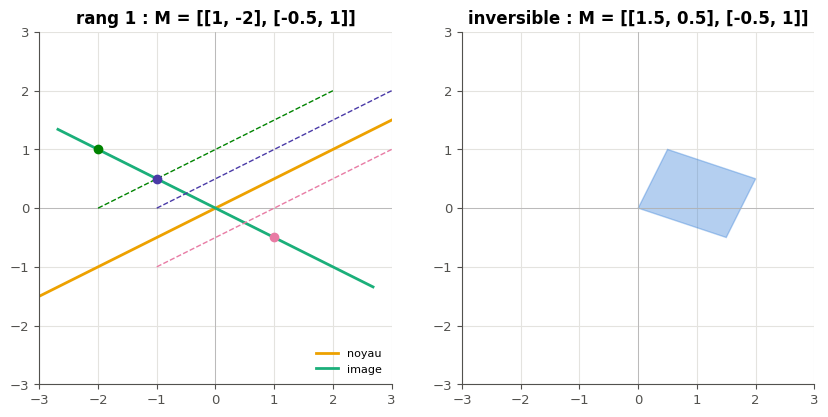

In [35]:
from matplotlib.patches import Polygon

mymath = wbm.load_mymath("ref")


def draw_kernel_and_image(ax, M):
    """In ax: the image of the unit square (a Polygon), and for a singular M its kernel, its image and three segments."""
    M = np.asarray(M, dtype=float)
    square = np.array([[0, 0], [1, 0], [1, 1], [0, 1]], dtype=float) @ M.T
    ax.add_patch(Polygon(square, closed=True, facecolor="C0", alpha=0.35, edgecolor="C0"))
    ax.axhline(0, color="0.7", lw=0.6)
    ax.axvline(0, color="0.7", lw=0.6)
    N = mymath.linmaps.null_space_basis(M)
    if N.shape[1] == 0:                                    # invertible: the kernel is {0}
        return
    k = N[:, 0]
    t = np.array([-2.0, 2.0])
    ax.plot(t * k[0], t * k[1], color="C3", lw=2, label="noyau")
    column = M[:, np.argmax(np.abs(M).sum(axis=0))]        # a non-zero column spans the image
    s = 3 / np.linalg.norm(column) * np.array([-1.0, 1.0])
    ax.plot(s * column[0], s * column[1], color="C2", lw=2, label="image")
    for i, p in enumerate(np.array([[1, 0], [0, 1], [1, 1]], dtype=float)):
        segment = p + np.outer([-1.0, 1.0], k)
        ax.plot(segment[:, 0], segment[:, 1], color=f"C{i + 4}", ls="--", lw=1, label="_nolegend_")
        image = M @ p
        ax.plot(image[0], image[1], "o", color=f"C{i + 4}", label="_nolegend_")


matrices_32 = [("rang 1", [[1, -2], [-0.5, 1]]), ("inversible", [[1.5, 0.5], [-0.5, 1]])]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
try:
    for ax, (name, M) in zip(axes, matrices_32):
        draw_kernel_and_image(ax, M)
        ax.set(title=f"{name} : M = {M}", aspect="equal", xlim=(-3, 3), ylim=(-3, 3))
        if ax.get_legend_handles_labels()[0]:
            ax.legend(loc="lower right", fontsize=8)
except BaseException:
    plt.close(fig)
    raise
plt.show()

**Vérifications automatiques** (sur trois matrices, dans des axes neufs).

In [36]:
with checked("M12a.32 vérifications"):
    problems = []
    for M_t, singular_t in [([[1, -2], [-0.5, 1]], True), ([[1.5, 0.5], [-0.5, 1]], False), ([[0, 0], [3, 1]], True)]:
        fig_t, ax_t = plt.subplots()
        try:
            created = drawn(lambda: draw_kernel_and_image(ax_t, M_t))
            labels_t = {line.get_label(): line for line in ax_t.lines}
            polygons_t = [p for p in ax_t.patches if hasattr(p, "get_xy")]
        finally:
            plt.close(fig_t)
        M_arr = np.array(M_t, dtype=float)
        if created:
            problems.append("draw_kernel_and_image ouvre sa propre figure : dessine dans l'axe reçu")
            break
        corners = np.array([[0, 0], [1, 0], [1, 1], [0, 1]], dtype=float)
        if not polygons_t or not np.allclose(np.asarray(polygons_t[0].get_xy(), dtype=float)[:4], corners @ M_arr.T,
                                             atol=1e-9):
            problems.append(f"pour M = {M_t}, le premier polygone n'a pas pour sommets les images de (0, 0), (1, 0), "
                            "(1, 1), (0, 1), dans cet ordre")
            break
        if singular_t:
            if "noyau" not in labels_t or "image" not in labels_t:
                problems.append(f"pour M = {M_t}, il manque une ligne de label « noyau » ou « image »")
                break
            ker_pts = np.column_stack([labels_t["noyau"].get_xdata(), labels_t["noyau"].get_ydata()]).astype(float)
            img_pts = np.column_stack([labels_t["image"].get_xdata(), labels_t["image"].get_ydata()]).astype(float)
            if len(ker_pts) < 2 or np.ptp(ker_pts, axis=0).max() < 1e-9 or not np.allclose(ker_pts @ M_arr.T, 0, atol=1e-9):
                problems.append(f"pour M = {M_t}, les points de la ligne « noyau » ne vérifient pas M x = 0 (ou la "
                                "ligne est réduite à un point)")
                break
            column = M_arr[:, np.argmax(np.abs(M_arr).sum(axis=0))]
            cross = img_pts[:, 0] * column[1] - img_pts[:, 1] * column[0]
            if len(img_pts) < 2 or np.ptp(img_pts, axis=0).max() < 1e-9 or not np.allclose(cross, 0, atol=1e-9):
                problems.append(f"pour M = {M_t}, la ligne « image » n'est pas portée par une colonne de M")
                break
        elif "noyau" in labels_t:
            problems.append(f"pour M = {M_t}, inversible, le noyau est {{0}} : pas de ligne « noyau »")
            break
    if problems:
        print("❌ Ex M12a.32 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M12a.32 : le carré, le noyau et l'image sont justes, pour trois matrices.")

✅ Ex M12a.32 : le carré, le noyau et l'image sont justes, pour trois matrices.


💡 Pour $\mathbf{M} = \begin{pmatrix} 1 & -2 \\ -0{,}5 & 1 \end{pmatrix}$, la seconde colonne vaut $-2$ fois la première : rang 1. Le noyau est la droite dirigée par $(2, 1)$, l'image celle dirigée par $(1 ;\ -0{,}5)$. Le carré unité devient un segment de l'image. Chaque segment $\mathbf{p} + t\,\mathbf{k}$ est envoyé sur $\mathbf{M}\mathbf{p} + t\,\mathbf{M}\mathbf{k} = \mathbf{M}\mathbf{p}$ : un seul point, sur la droite image. Les points d'un tel segment ont tous la même image : aucune application ne peut les séparer après coup, donc aucune ne défait $\mathbf{M}$. La matrice inversible déforme le carré en un parallélogramme, sans rien écraser.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §2, §6, §7 et §8. Trois erreurs à trouver, un test de propriétés, puis des relations cachées à retrouver sans en inventer.

### Ex M12a.33 — Chasse à l'erreur : une « base » liée, un noyau faux, S⁻¹AS écrit à l'envers 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans du code les erreurs classiques sur les bases, les noyaux et les changements de base, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §2, §6, §7 et §8 · **Parcours :** C

Un collègue a écrit six lignes, chacune avec un commentaire qui dit ce qu'elle doit calculer. Trois lignes ne calculent pas ce que dit leur commentaire. **Sans exécuter de code**, trouve-les.

```python
A = np.array([[1.0, 2.0, 1.0], [2.0, 4.0, 3.0]])                     # a 2 × 3 matrix
u, v = np.array([1.0, 0.0, 1.0]), np.array([0.0, 1.0, 1.0])
B = np.column_stack([u, v, u + v])           # (A) a basis of R^3 that completes (u, v): its rank
R = np.array([[1.0, 2.0, 0.0], [0.0, 0.0, 1.0]])                     # the reduced form of A
k = np.array([R[0, 1], 1.0, 0.0])            # (B) the basis vector of ker A with x2 = 1: k[0]
e3 = np.array([0.0, 0.0, 1.0])
c = np.linalg.solve(np.column_stack([u, v, e3]), np.array([2.0, 3.0, 4.0]))   # (C) coordinates of (2, 3, 4) in (u, v, e3): c[2]
M = np.array([[2.0, 1.0], [0.0, 3.0]])
S = np.array([[1.0, 1.0], [0.0, 1.0]])
D = S @ M @ np.linalg.inv(S)                 # (D) the matrix of x -> M x in the basis of the columns of S: D[0, 1]
n = A.shape[1] - 2                           # (E) dim ker A, by the rank theorem (A has rank 2)
y = np.linalg.solve(M, np.array([5.0, 6.0]) - np.array([1.0, 0.0]))         # (F) phi^-1(5, 6) for phi(x) = M x + (1, 0): y[0]
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) pour chacune des six lignes, de (A) à (F), la bonne valeur de ce que dit son commentaire (une liste de 6 nombres).

Dans ta copie : pour chaque ligne fausse, quelle erreur a été faite, et comment la corriger ? Laquelle des trois s'exécute sans erreur **et** sans valeur absurde, et pourquoi est-elle la plus dangereuse ?

In [37]:
answer_M12a_33a = "ABD"
A = np.array([[1.0, 2.0, 1.0], [2.0, 4.0, 3.0]])
u, v = np.array([1.0, 0.0, 1.0]), np.array([0.0, 1.0, 1.0])
B = np.column_stack([u, v, np.array([1.0, 0.0, 0.0])])   # (A) u + v is in Vect(u, v): complete with e1 instead
R = np.array([[1.0, 2.0, 0.0], [0.0, 0.0, 1.0]])
k = np.array([-R[0, 1], 1.0, 0.0])           # (B) x_p = −R[i, j]: the minus sign
e3 = np.array([0.0, 0.0, 1.0])
c = np.linalg.solve(np.column_stack([u, v, e3]), np.array([2.0, 3.0, 4.0]))   # (C) correct
M = np.array([[2.0, 1.0], [0.0, 3.0]])
S = np.array([[1.0, 1.0], [0.0, 1.0]])
D = np.linalg.solve(S, M @ S)                # (D) S⁻¹MS, not SMS⁻¹
n = A.shape[1] - 2                           # (E) correct
y = np.linalg.solve(M, np.array([5.0, 6.0]) - np.array([1.0, 0.0]))         # (F) correct
answer_M12a_33b = [int(np.linalg.matrix_rank(B)), float(k[0]), float(c[2]), float(D[0, 1]), n, float(y[0])]
print(answer_M12a_33a, answer_M12a_33b)

ABD [3, -2.0, -1.0, 0.0, 1, 1.0]


In [38]:
wbm.record("M12a.33a", "ABD",
           mistakes={"il manque une ligne fautive : calcule le rang de chaque famille appelée « base »": "BD",
                     "il manque une ligne fautive : vérifie A fois chaque vecteur appelé « noyau »": "AD",
                     "il manque une ligne fautive : relis l'ordre des facteurs d'un changement de base": "AB",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABCD", "ABDE", "ABDF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : calcule le rang de chaque famille appelée « base »": {"BCD", "BDE", "BDF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie A fois chaque vecteur appelé « noyau »": {"ACD", "ADE", "ADF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : relis l'ordre des facteurs d'un changement de base": {"ABC", "ABE", "ABF"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "B", "D"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"C", "E", "F", "AC", "AE", "AF", "BC", "BE", "BF", "CD", "CE", "CF", "DE", "DF", "EF", "ACE", "ACF", "AEF", "BCE", "BCF", "BEF", "CDE", "CDF", "CEF", "DEF", "ABCE", "ABCF", "ABEF", "ACDE", "ACDF", "ACEF", "ADEF", "BCDE", "BCDF", "BCEF", "BDEF", "CDEF", "ABCEF", "ACDEF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDE", "ABCDF", "ABDEF", "ABCDEF"}})
VALUES_33 = [3.0, -2.0, -1.0, 0.0, 1.0, 1.0]
wbm.record("M12a.33b", VALUES_33, decimals=4,
           mistakes={"(A) : u + v est dans Vect(u, v) ; une vraie base de ℝ³ a pour rang 3": [2.0] + VALUES_33[1:],
                      "(B) : x_p = −R[i, j], avec le signe moins": VALUES_33[:1] + [2.0] + VALUES_33[2:],
                      "(D) : la matrice dans la base S est S⁻¹MS, pas SMS⁻¹": VALUES_33[:3] + [2.0] + VALUES_33[4:]})

WBM_ANSWER {"hash": "f0d3663d2795c3f76d0200a6d2bd8e01b0df022df4db8da1b7b458c01f6ca4be", "id": "M12a.33a", "kind": "str", "mistakes": {"0341e1f061ffe0de6adceab4299d1cf0a2c61a86910eac891b7a303946fe08a9": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "104001a4f0368b257f361b70c5573237248c76f5ae41c4478ed79cf1c026dc6e": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "1b0335782e427ca2d6bcefd7c11e4545a2de3df3e6ec5deecd7d2f64c9ba45c0": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "1b455b3535fa1b0e4bac4f591e2e1ed44114d7118540c655c03af49d0391a2b9": "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie A fois chaque vecteur appelé « noyau »", "1ee4dc07efb8f87687ac9a1223efd41405fe44abc478125e6a8ccc3c15127d1e": "il manque des lignes fautives, et 

💡 (A) $\mathbf{u} + \mathbf{v}$ est dans $\operatorname{Vect}(\mathbf{u}, \mathbf{v})$ : la « base » est liée, de rang 2 ; $\mathbf{e}_1$ complète $(\mathbf{u}, \mathbf{v})$, et une base de $\mathbb{R}^3$ a pour rang 3. (B) Le vecteur du noyau a $x_1 = -R_{12} = -2$ : $(-2, 1, 0)$, et $\mathbf{A}(2, 1, 0) = (4, 8) \ne \mathbf{0}$ trahit l'erreur de signe. (C) est juste : $c_1 = 2$, $c_2 = 3$, $c_1 + c_2 + c_3 = 4$, donc $c_3 = -1$. (D) $\mathbf{S}\mathbf{M}\mathbf{S}^{-1} = \begin{pmatrix} 2 & 2 \\ 0 & 3 \end{pmatrix}$ ; la bonne matrice, $\mathbf{S}^{-1}\mathbf{M}\mathbf{S} = \begin{pmatrix} 2 & 0 \\ 0 & 3 \end{pmatrix}$, est diagonale, car $\mathbf{M}(1, 0) = 2\,(1, 0)$ et $\mathbf{M}(1, 1) = 3\,(1, 1)$. C'est l'erreur la plus dangereuse : elle s'exécute et rend une matrice plausible. (E) $3 - 2 = 1$. (F) $\varphi^{-1}(5, 6) = \mathbf{M}^{-1}(4, 6) = (1, 2)$.

### Ex M12a.34 — Un test de propriété : A fois une base du noyau donne 0, et le théorème du rang sur des matrices aléatoires 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire un test fondé sur des propriétés vérifiées sur des matrices aléatoires de rang choisi, et voir quelle propriété attrape quelle erreur.  
**Prérequis :** fiche §6 ; Ex M12a.26 et M12a.27 · **Parcours :** C

Les tests de `mymath` comparent tes fonctions à SymPy. On peut aussi vérifier des **propriétés** que tout résultat juste doit avoir. Écris :
- `check_kernel_and_rank(null_space_basis, column_space_basis, seed, trials=10)` : avec `rng = np.random.default_rng(seed)`, répète `trials` fois : tire $m$ et $n$ entre 1 et 6 (`rng.integers(1, 7, size=2)`), un rang $r$ entre 0 et $\min(m, n)$ (`rng.integers(0, min(m, n) + 1)`), et la matrice entière $\mathbf{A} = \mathbf{L}\mathbf{C}$, produit de deux matrices d'entiers tirés entre $-3$ et 3, de formes $(m, r)$ et $(r, n)$ (`rng.integers(-3, 4, size=...)`, converties en floats). Avec `N = null_space_basis(A)` et `Q = column_space_basis(A)`, vérifie par des `assert` (avec un message) : (1) $\mathbf{A}\mathbf{N} = \mathbf{0}$ à $10^{-9}$ près ; (2) le théorème du rang, `N.shape[1] + Q.shape[1] == n` ; (3) les colonnes de `N` sont libres (`np.linalg.matrix_rank(N) == N.shape[1]`, permis ici : c'est le test, pas `linmaps.py` ; `matrix_rank` refuse un tableau sans colonne, et un noyau $\{\mathbf{0}\}$ n'a rien à vérifier) ;
- `test_kernel_and_rank()` : le test au format pytest, sans argument, qui appelle `check_kernel_and_rank` avec les fonctions de **ta** librairie (`mymath.linmaps`) et une graine fixe.

La cellule fournie définit deux copies fausses : un noyau qui a la bonne forme mais ne contient que des zéros, et une « base de l'image » qui garde toutes les colonnes. La vérification lance ton test sur les bonnes fonctions (la référence) et sur chaque copie fausse, pour 20 graines.

Dans ta copie : quelle propriété attrape le noyau fait de zéros, et pourquoi les deux autres le laissent-elles passer ? Quelle propriété attrape l'image faite de toutes les colonnes ? Une fonction fausse pourrait-elle passer les trois propriétés ? (Pense à un noyau juste, mais rendu avec ses colonnes multipliées par 2.)

In [39]:
def null_space_zeros(A, tol=1e-10):          # a copy with a bug: the right shape, but only zeros
    A = np.asarray(A, dtype=float)
    rank = np.linalg.matrix_rank(A)
    return np.zeros((A.shape[1], A.shape[1] - rank))


def column_space_all(A, tol=1e-10):          # a copy with another bug: every column, pivot or not
    return np.array(A, dtype=float)

In [40]:
mymath = wbm.load_mymath("ref")


def check_kernel_and_rank(null_space_basis, column_space_basis, seed, trials=10):
    """Assert A N = 0, the rank theorem and independent kernel columns, on `trials` random integer matrices."""
    rng = np.random.default_rng(seed)
    for _ in range(trials):
        m, n = rng.integers(1, 7, size=2)
        r = rng.integers(0, min(m, n) + 1)
        A = (rng.integers(-3, 4, size=(m, r)) @ rng.integers(-3, 4, size=(r, n))).astype(float)
        N = np.asarray(null_space_basis(A), dtype=float)
        Q = np.asarray(column_space_basis(A), dtype=float)
        assert N.shape[0] == n and np.allclose(A @ N, 0, rtol=0, atol=1e-9), (
            f"expected A N = 0 for A of shape {A.shape}, got a largest |A N| of {np.max(np.abs(A @ N), initial=0):.1e}")
        assert N.shape[1] + Q.shape[1] == n, (
            f"expected dim ker + rank = {n} for A of shape {A.shape}, got {N.shape[1]} + {Q.shape[1]}")
        assert N.shape[1] == 0 or np.linalg.matrix_rank(N) == N.shape[1], (
            f"expected independent kernel columns for A of shape {A.shape}, got a family of rank "
            f"{np.linalg.matrix_rank(N)} for {N.shape[1]} columns")


def test_kernel_and_rank():
    """The pytest test: check_kernel_and_rank on your null_space_basis and column_space_basis, with a fixed seed."""
    check_kernel_and_rank(mymath.linmaps.null_space_basis, mymath.linmaps.column_space_basis, seed=34)


test_kernel_and_rank()
print("the three properties hold for the reference")

the three properties hold for the reference


In [41]:
with checked("M12a.34 vérifications"):
    problems = []
    ref_34 = wbm.load_mymath("ref").linmaps

    def outcome(null_space_t, column_space_t, seed):
        """None if check_kernel_and_rank passes, else the message of its AssertionError."""
        try:
            check_kernel_and_rank(null_space_t, column_space_t, seed)
        except AssertionError as exc:
            return str(exc)
        return None

    passed = sum(outcome(ref_34.null_space_basis, ref_34.column_space_basis, seed) is None for seed in range(20))
    caught_zeros = [outcome(null_space_zeros, ref_34.column_space_basis, seed) for seed in range(20)]
    caught_all = [outcome(ref_34.null_space_basis, column_space_all, seed) for seed in range(20)]
    print(f"la bonne paire passe ton test {passed} fois sur 20 ; le noyau fait de zéros est attrapé "
          f"{sum(m is not None for m in caught_zeros)} fois sur 20 ; l'image faite de toutes les colonnes, "
          f"{sum(m is not None for m in caught_all)} fois sur 20")
    if passed < 20:
        problems.append("ton test échoue sur les bonnes fonctions : compare avec np.allclose (des flottants), et "
                        "vérifie tes formes")
    if sum(m is not None for m in caught_zeros) < 20:
        problems.append("ton test laisse passer un noyau fait de zéros : vérifie aussi que ses colonnes sont libres")
    if sum(m is not None for m in caught_all) < 20:
        problems.append("ton test laisse passer une image faite de toutes les colonnes : vérifie le théorème du rang, "
                        "nombre de colonnes de la base de l'image + nombre de colonnes de la base du noyau = n")
    if not problems and any(not (m or "").strip() for m in caught_zeros + caught_all):
        problems.append("ajoute un message à chaque assert (assert condition, message)")
    if not problems:
        try:
            test_kernel_and_rank()
        except AssertionError as exc:
            problems.append(f"test_kernel_and_rank échoue sur ta librairie : {exc}")
    if problems:
        print("❌ Ex M12a.34 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M12a.34 : ton test passe sur les bonnes fonctions et attrape les deux copies fausses.")

la bonne paire passe ton test 20 fois sur 20 ; le noyau fait de zéros est attrapé 20 fois sur 20 ; l'image faite de toutes les colonnes, 20 fois sur 20
✅ Ex M12a.34 : ton test passe sur les bonnes fonctions et attrape les deux copies fausses.


💡 Le noyau fait de zéros vérifie $\mathbf{A}\mathbf{N} = \mathbf{0}$ et le théorème du rang (il a la bonne forme) : seule la troisième propriété, des colonnes libres, l'attrape. L'image faite de toutes les colonnes a $n$ colonnes : avec un noyau non nul, la somme dépasse $n$, et le théorème du rang l'attrape (une matrice de rang plein en colonnes passe, d'où les tirages de rangs variés). Une base du noyau multipliée par 2 passe les trois propriétés : elle est fausse au sens de la docstring (la convention de SymPy), mais c'est encore une base du noyau. Un test de propriétés vérifie des conséquences de la bonne réponse ; pour la réponse elle-même, il faut un oracle, comme le font les tests de `mymath`.

### Ex M12a.35 — Défi : retrouver les relations linéaires exactes cachées entre les colonnes d'un tableau, sans en inventer 🏆 ★★★ ⏱️ 30 min
**Objectif :** trouver toutes les relations linéaires exactes entre les colonnes d'un tableau de données, quelles que soient les échelles des colonnes, sans prendre une relation approchée pour une relation exacte.  
**Prérequis :** fiche §4 et §6 ; Ex M12a.27 et M12a.31 · **Parcours :** C

La fonction fournie `make_hidden_table(seed)` fabrique un tableau de 150 exemples dont certaines colonnes sont des combinaisons **exactes** des autres (aux arrondis des flottants près), et une colonne qui n'est une combinaison des autres qu'**à $10^{-6}$ près** en relatif. Les colonnes ont des ordres de grandeur très différents (de $10^{-4}$ à $10^{6}$), et sont mélangées.

**L'objectif** : écrire `hidden_relations(X)`, qui rend une matrice de forme $(p, k)$ dont les colonnes forment une base de l'espace des relations **exactes** $\{\mathbf{c} : \mathbf{X}\mathbf{c} = \mathbf{0}\}$ : toutes les relations exactes, et aucune de trop (la relation à $10^{-6}$ près n'en est pas une). La vérification essaie ta fonction sur trois tableaux (`seed` = 35, 36 et 37) ; une dernière cellule enregistre si l'objectif est atteint sur les trois.

`null_space_basis(X)` avec sa tolérance absolue par défaut échoue : les arrondis d'une colonne de l'ordre de $10^6$ dépassent $10^{-10}$, et le bruit d'une colonne de l'ordre de $10^{-4}$ passe sous $10^{-10}$ (M12a.31). Pistes : mettre les colonnes à la même échelle (diviser chaque colonne par sa norme, une matrice diagonale $\mathbf{D}$ : $\mathbf{X}\mathbf{D}^{-1}$), chercher le noyau de ce tableau avec une tolérance bien choisie entre les arrondis (vers $10^{-15}$) et le bruit (vers $10^{-6}$), puis revenir aux relations du tableau de départ (si $\mathbf{X}\mathbf{D}^{-1}\mathbf{y} = \mathbf{0}$, alors $\mathbf{c} = \mathbf{D}^{-1}\mathbf{y}$ vérifie $\mathbf{X}\mathbf{c} = \mathbf{0}$).

Dans ta copie : quelle tolérance as-tu choisie, et pourquoi ? Que se passe-t-il avec une tolérance de $10^{-5}$, et avec la tolérance par défaut sans changer d'échelle ? Sur de vraies données mesurées, comment choisirais-tu la tolérance ?

In [42]:
def make_hidden_table(seed, n=150):
    """A (n, p) table whose columns hide exact linear relations, and one relation that is only almost exact."""
    rng = np.random.default_rng(seed)
    q, k = int(rng.integers(3, 5)), int(rng.integers(1, 4))      # q free directions, k exact relations
    G = np.zeros((q, q + k + 1))
    G[:, :q] = np.eye(q)
    for j in range(q, q + k + 1):
        column = np.zeros(q)
        while np.count_nonzero(column) < 2:
            column = rng.integers(-3, 4, size=q).astype(float)
        G[:, j] = column
    scales = 10.0 ** rng.integers(-2, 4, size=q + k + 1)
    scales[q], scales[q + k] = 1e6, 1e-4
    X = (rng.normal(size=(n, q)) @ G) * scales
    X[:, q + k] += 1e-6 * np.linalg.norm(X[:, q + k]) / np.sqrt(n) * rng.normal(size=n)   # almost, not exactly
    return X[:, rng.permutation(q + k + 1)]

In [43]:
mymath = wbm.load_mymath("ref")


def hidden_relations(X):
    """A (p, k) matrix whose columns are a basis of the exact relations X c = 0 between the columns of X."""
    X = np.asarray(X, dtype=float)
    norms = np.linalg.norm(X, axis=0)                  # D: every column brought to norm 1
    Y = mymath.linmaps.null_space_basis(X / norms, tol=1e-9)
    return Y / norms[:, None]                          # c = D⁻¹ y


for seed in (35, 36, 37):
    X_35 = make_hidden_table(seed)
    print(seed, X_35.shape, "default tol, raw columns:", mymath.linmaps.null_space_basis(X_35).shape[1],
          "· scaled, tol 1e-9:", hidden_relations(X_35).shape[1],
          "· scaled, tol 1e-5:", mymath.linmaps.null_space_basis(X_35 / np.linalg.norm(X_35, axis=0), tol=1e-5).shape[1])

35 (150, 6) default tol, raw columns: 1 · scaled, tol 1e-9: 2 · scaled, tol 1e-5: 3
36 (150, 5) default tol, raw columns: 0 · scaled, tol 1e-9: 1 · scaled, tol 1e-5: 2
37 (150, 7) default tol, raw columns: 3 · scaled, tol 1e-9: 3 · scaled, tol 1e-5: 4


In [44]:
wbm.record("M12a.35", True,
           mistakes={"l'objectif n'est pas atteint sur les trois tables : la cellule du défi dit pourquoi": False})

WBM_ANSWER {"hash": "45f728c9a2d725dbaa0d08296d0da2487ed66592a705c5b83639e645e4947fc5", "id": "M12a.35", "kind": "bool", "mistakes": {"9c6e5384099c3fed8c0c6e88e73ff167d73d6bdbb60b5c5b16d372ecd06fa270": "l'objectif n'est pas atteint sur les trois tables : la cellule du défi dit pourquoi"}}
📝 Ex M12a.35 : réponse enregistrée (bool).


In [45]:
with checked("M12a.35 défi"):
    problems, ok_35 = [], False
    for seed_t in (35, 36, 37):
        X_t = make_hidden_table(seed_t)
        rng_t = np.random.default_rng(seed_t)
        rng_t.integers(3, 5)
        k_true = int(rng_t.integers(1, 4))
        try:
            N_t = np.asarray(hidden_relations(X_t.copy()), dtype=float)
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            problems.append(f"hidden_relations lève {type(exc).__name__} ({exc})")
            break
        p_t = X_t.shape[1]
        if N_t.ndim != 2 or N_t.shape[0] != p_t:
            problems.append(f"table {seed_t} : hidden_relations rend la forme {N_t.shape}, pas ({p_t}, k)")
            break
        norms_t = np.linalg.norm(X_t, axis=0)
        scaled_t = N_t * norms_t[:, None]                  # the relations between the normalized columns
        if N_t.shape[1] < k_true:
            problems.append(f"table {seed_t} : {N_t.shape[1]} relation(s) trouvée(s), il en manque : une colonne d'une "
                            "échelle très différente des autres cache peut-être une relation exacte")
            break
        if N_t.shape[1] > k_true:
            problems.append(f"table {seed_t} : {N_t.shape[1]} relations, c'est trop : une relation vraie à 1e-6 près "
                            "seulement n'est pas exacte ; ta tolérance est trop large, ou elle dépend de l'échelle")
            break
        if k_true:
            col_norms_t = np.linalg.norm(scaled_t, axis=0)
            residual_t = np.linalg.norm((X_t / norms_t) @ scaled_t, axis=0) / col_norms_t
            if np.any(col_norms_t == 0) or residual_t.max() > 1e-8:
                problems.append(f"table {seed_t} : une relation rendue n'est pas exacte (résidu relatif "
                                f"{residual_t.max():.1e})")
                break
            if np.linalg.matrix_rank(scaled_t / col_norms_t, tol=1e-6) < k_true:
                problems.append(f"table {seed_t} : les relations rendues ne sont pas libres")
                break
        print(f"table {seed_t} : {X_t.shape}, {N_t.shape[1]} relation(s) exacte(s) retrouvée(s)")
    if problems:
        print("❌ Ex M12a.35 : " + " ; ".join(problems) + ".")
    else:
        ok_35 = True
        print("✅ Ex M12a.35 : défi réussi : toutes les relations exactes, et aucune de trop, dans les trois tables.")

table 35 : (150, 6), 2 relation(s) exacte(s) retrouvée(s)
table 36 : (150, 5), 1 relation(s) exacte(s) retrouvée(s)
table 37 : (150, 7), 3 relation(s) exacte(s) retrouvée(s)
✅ Ex M12a.35 : défi réussi : toutes les relations exactes, et aucune de trop, dans les trois tables.


💡 Sur les colonnes brutes, la tolérance absolue $10^{-10}$ se trompe dans les deux sens : elle manque des relations (les arrondis d'une colonne de l'ordre de $10^6$ font des pivots de l'ordre de $10^{-10}$) et peut en inventer (le bruit d'une colonne de l'ordre de $10^{-4}$ tombe sous la tolérance). Une fois chaque colonne divisée par sa norme, les pivots résiduels des relations exactes valent environ $10^{-15}$ et celui de la relation approchée environ $10^{-7}$ : toute tolérance entre $10^{-12}$ et $10^{-8}$ les sépare ; $10^{-5}$ prend la relation approchée pour exacte. Sur des données mesurées, la tolérance se règle sur la précision des mesures, après avoir mis les colonnes à la même échelle.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu reconnaître un sous-espace, et décider si une famille est libre ?
2. Sais-tu extraire une base, et calculer des coordonnées dans une base ?
3. Sais-tu calculer un rang, et majorer celui d'un produit ?
4. Sais-tu écrire la matrice d'une application linéaire, et calculer un noyau et une image ?
5. Sais-tu changer de base, et inverser une application affine ?

**La suite** : le chapitre 12 de workbookIA (préparation des données), en parallèle de M12b, l'orthogonalité et les projections.